# Notebook 04: Carport Data Exploratie
___
In dit Jupyter Notebook wordt de exploratie gedaan op basis van de dataset uit het bestand [carport.parquet](./locatie_data/carport.parquet)

#### Uitgevoerde taken zijn:
* Data Exploratie
* Data Onderzoek
* Data Aanpassing
* Data Aanvulling

### Inladen
___
1. Libraries importeren en de map met de data vastleggen

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

#Map waar de parquet bestanden staan
DATA_DIR = Path.cwd().parent / "locatie_data"

2. De carport dataset inladen

In [2]:
df_carport = pd.read_parquet(DATA_DIR / "carport.parquet")

3. Eerste rijen bekijken

In [3]:
df_carport.head()

,timestamp,CO2EQ,CTYPE,ENAME,ETYPE,source_zip,source_csv,source_folder,CTYPEC,ESTYPE,...,ENE,POW,CO2,CO2_EXP,CO2_IMP,ENE_EXP,ENE_IMP,ENE_CNT_EXP,ENE_CNT_IMP,PRICE
0,2024-03-08 01:00:00+01:00,NaN,electricity,hoofdaansluiting-e4393cd3dfdb,powermeter,240308_hoofdaansluiting-e4393cd3dfdb_854d89ad9...,240308_hoofdaansluiting-e4393cd3dfdb_854d89ad9...,hoofdaansluiting-e4393cd3dfdb,supply,NaN,...,NaN,370.263636,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-03-08 01:00:00+01:00,NaN,electricity,laadpaal1-e4393cd3dfdb,evcharger,240308_laadpaal1-e4393cd3dfdb_ef67dd7cc10861d9...,240308_laadpaal1-e4393cd3dfdb_ef67dd7cc10861d9...,laadpaal1-e4393cd3dfdb,NaN,NaN,...,NaN,0.000353,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024-03-08 01:00:00+01:00,NaN,electricity,laadpaal2-e4393cd3dfdb,evcharger,240308_laadpaal2-e4393cd3dfdb_ef67dd7cc10861d9...,240308_laadpaal2-e4393cd3dfdb_ef67dd7cc10861d9...,laadpaal2-e4393cd3dfdb,NaN,NaN,...,NaN,316.100317,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-03-08 01:00:00+01:00,NaN,electricity,laadpaal3-e4393cd3dfdb,evcharger,240308_laadpaal3-e4393cd3dfdb_ef67dd7cc10861d9...,240308_laadpaal3-e4393cd3dfdb_ef67dd7cc10861d9...,laadpaal3-e4393cd3dfdb,NaN,NaN,...,NaN,0.000465,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-03-08 01:00:00+01:00,NaN,electricity,overigverbruik-e4393cd3dfdb,powermeter,240308_overigverbruik-e4393cd3dfdb_a7612155098...,240308_overigverbruik-e4393cd3dfdb_a7612155098...,overigverbruik-e4393cd3dfdb,NaN,NaN,...,NaN,-10.350000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Algemene controle
___
1. Grootte, volgorde en datatypes van de dataset bekijken

In [4]:
print("Shape:", df_carport.shape)

#Staan de timestamps op volgorde?
print("Chronologisch:", df_carport["timestamp"].is_monotonic_increasing)

df_carport.info()

Shape: (4888431, 22)
Chronologisch: True
<class 'pandas.DataFrame'>
RangeIndex: 4888431 entries, 0 to 4888430
Data columns (total 22 columns):
 #   Column         Dtype                           
---  ------         -----                           
 0   timestamp      datetime64[us, Europe/Amsterdam]
 1   CO2EQ          float64                         
 2   CTYPE          str                             
 3   ENAME          str                             
 4   ETYPE          str                             
 5   source_zip     str                             
 6   source_csv     str                             
 7   source_folder  str                             
 8   CTYPEC         str                             
 9   ESTYPE         str                             
 10  forecast.ENE   float64                         
 11  forecast.POW   float64                         
 12  ENE            float64                         
 13  POW            float64                         
 14  CO2 

2. Aantal rijen per ENAME

In [5]:
df_carport["ENAME"].value_counts()

ENAME
totaalverbruik-e4393cd3dfdb            361138
laadpaal2-e4393cd3dfdb                 360889
laadpaal1-e4393cd3dfdb                 360517
hoofdaansluiting-e4393cd3dfdb          358041
overigverbruik-e4393cd3dfdb            356967
laadpaal3-e4393cd3dfdb                 353343
zonnepanelen-e4393cd3dfdb              345473
wijktotaalverbruik-e4393cd3dfdb        318470
wijkvirtuelehoofdmeter-e4393cd3dfdb    318195
wijktotaleopwek-e4393cd3dfdb           309497
laadpaalbus-e4393cd3dfdb               282308
laadpaaltesla-e4393cd3dfdb             281698
victronaccu-e4393cd3dfdb               259754
co2ele_combined                        158933
priceele_c911efafaa                    147634
odectprice_c911efafaa                   95109
laadpaal4-e4393cd3dfdb                  92220
laadpaal5-e4393cd3dfdb                  92220
forec-totaalverbruik-e4393cd3dfdb       17294
forec-zonnepanelen-e4393cd3dfdb         17294
priceele_123456                          1437
Name: count, dtype: int64

3. Aantal ingevulde waarden per kolom, per ENAME

> Hiermee is te zien welke kolommen bij welk apparaat horen

In [6]:
ingevulde_kolommen_per_ename = (df_carport.groupby("ENAME").count())

ingevulde_kolommen_per_ename

,timestamp,CO2EQ,CTYPE,ETYPE,source_zip,source_csv,source_folder,CTYPEC,ESTYPE,forecast.ENE,...,ENE,POW,CO2,CO2_EXP,CO2_IMP,ENE_EXP,ENE_IMP,ENE_CNT_EXP,ENE_CNT_IMP,PRICE
ENAME,,,,,,,,,,,,,,,,,,,,,
co2ele_combined,158933,158933,158933,158933,158933,158933,158933,0,0,0,...,0,0,0,0,0,0,0,0,0,0
forec-totaalverbruik-e4393cd3dfdb,17294,0,17294,17294,17294,17294,17294,17294,17294,8647,...,0,0,0,0,0,0,0,0,0,0
forec-zonnepanelen-e4393cd3dfdb,17294,0,17294,17294,17294,17294,17294,17294,17294,8647,...,0,0,0,0,0,0,0,0,0,0
hoofdaansluiting-e4393cd3dfdb,358041,0,358041,358041,358041,358041,358041,219821,0,0,...,218225,203710,138825,78271,84446,145952,152130,141751,141749,0
laadpaal1-e4393cd3dfdb,360517,0,360517,360517,360517,360517,360517,138108,0,0,...,208982,208994,135304,0,70559,0,138235,0,138277,0
laadpaal2-e4393cd3dfdb,360889,0,360889,360889,360889,360889,360889,138107,0,0,...,209143,209155,135301,0,70461,0,138135,0,138177,0
laadpaal3-e4393cd3dfdb,353343,0,353343,353343,353343,353343,353343,134340,0,0,...,204459,204469,134774,0,66413,0,131748,0,131789,0
laadpaal4-e4393cd3dfdb,92220,0,92220,92220,92220,92220,92220,43790,0,0,...,40709,40709,4151,0,6958,0,48416,0,48429,0
laadpaal5-e4393cd3dfdb,92220,0,92220,92220,92220,92220,92220,43790,0,0,...,40709,40709,4151,0,6958,0,48417,0,48430,0


### Overzicht van de meetreeksen
___
1. Per ENAME het aantal rijen, unieke timestamps, eerste en laatste meting

> Dubbele timestamps = aantal rijen - unieke timestamps

In [7]:
#Samenvatting van de timestamps per ENAME
overzicht = (df_carport.groupby("ENAME").agg(
        aantal_rijen=("timestamp", "size"),
        unieke_timestamps=("timestamp", "nunique"),
        eerste_meting=("timestamp", "min"),
        laatste_meting=("timestamp", "max")
    )
)

#Extra rijen doordat een timestamp vaker voorkomt
overzicht["dubbele_timestamps"] = (overzicht["aantal_rijen"] - overzicht["unieke_timestamps"])

overzicht.sort_values("aantal_rijen", ascending=False)

,aantal_rijen,unieke_timestamps,eerste_meting,laatste_meting,dubbele_timestamps
ENAME,,,,,
totaalverbruik-e4393cd3dfdb,361138,222913,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,138225
laadpaal2-e4393cd3dfdb,360889,222781,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,138108
laadpaal1-e4393cd3dfdb,360517,222408,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,138109
hoofdaansluiting-e4393cd3dfdb,358041,219820,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,138221
overigverbruik-e4393cd3dfdb,356967,220886,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,136081
laadpaal3-e4393cd3dfdb,353343,219002,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,134341
zonnepanelen-e4393cd3dfdb,345473,207287,2024-03-08 01:05:00+01:00,2026-09-07 08:05:00+02:00,138186
wijktotaalverbruik-e4393cd3dfdb,318470,182389,2024-03-08 21:55:00+01:00,2026-09-07 08:05:00+02:00,136081
wijkvirtuelehoofdmeter-e4393cd3dfdb,318195,182114,2024-03-09 20:55:00+01:00,2026-09-07 08:05:00+02:00,136081


### Totaalverbruik bekijken
___
1. Alleen de rijen van totaalverbruik apart zetten

In [8]:
TOTAALVERBRUIK = "totaalverbruik-e4393cd3dfdb"

#Aparte dataframe met alleen totaalverbruik, gesorteerd op tijd
df_totaal = (df_carport[df_carport["ENAME"] == TOTAALVERBRUIK].copy()
             .sort_values("timestamp").reset_index(drop=True)
)

print("Aantal rijen:", len(df_totaal))
print("Unieke timestamps:", df_totaal["timestamp"].nunique())
print("Dubbele timestamps:", len(df_totaal) - df_totaal["timestamp"].nunique())

df_totaal.head()

Aantal rijen: 361138
Unieke timestamps: 222913
Dubbele timestamps: 138225


,timestamp,CO2EQ,CTYPE,ENAME,ETYPE,source_zip,source_csv,source_folder,CTYPEC,ESTYPE,...,ENE,POW,CO2,CO2_EXP,CO2_IMP,ENE_EXP,ENE_IMP,ENE_CNT_EXP,ENE_CNT_IMP,PRICE
0,2024-03-08 01:00:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,NaN,786.222222,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-03-08 01:05:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,65.518519,3108.181818,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024-03-08 01:10:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,259.015152,3253.111111,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-03-08 01:15:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,271.092593,3249.264706,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-03-08 01:20:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,270.772059,1446.435897,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


2. Alle rijen met een dubbele timestamp bekijken

> Vaak staat de meting verdeeld over 2 rijen (bv. één rij met COST en één rij met POW)

In [9]:
#keep=False zodat beide rijen van een dubbele timestamp getoond worden
df_dubbel = (df_totaal[df_totaal["timestamp"].duplicated(keep=False)].sort_values("timestamp"))

df_dubbel

,timestamp,CO2EQ,CTYPE,ENAME,ETYPE,source_zip,source_csv,source_folder,CTYPEC,ESTYPE,...,ENE,POW,CO2,CO2_EXP,CO2_IMP,ENE_EXP,ENE_IMP,ENE_CNT_EXP,ENE_CNT_IMP,PRICE
59080,2024-10-05 20:10:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,336.961806,4056.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
59081,2024-10-05 20:10:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,NaN,3646.764706,160.393819,NaN,NaN,NaN,NaN,NaN,NaN,NaN
80037,2025-01-14 09:20:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,250114_totaalverbruik-e4393cd3dfdb_1e06bd2cb94...,250114_totaalverbruik-e4393cd3dfdb_1e06bd2cb94...,totaalverbruik-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
80038,2025-01-14 09:20:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,250114_totaalverbruik-e4393cd3dfdb_1e06bd2cb94...,250114_totaalverbruik-e4393cd3dfdb_1e06bd2cb94...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,-2.442371,-24.105820,-0.769347,NaN,NaN,NaN,NaN,0.0,35447531.0,NaN
80039,2025-01-14 09:25:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,250114_totaalverbruik-e4393cd3dfdb_1e06bd2cb94...,250114_totaalverbruik-e4393cd3dfdb_1e06bd2cb94...,totaalverbruik-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
356507,2026-06-20 03:45:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,0.000000,NaN,0.000000,0.0,0.0,0.0,0.0,0.0,19128467.0,NaN
356508,2026-06-20 03:50:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,totaalverbruik-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
356509,2026-06-20 03:50:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,0.000000,NaN,0.000000,0.0,0.0,0.0,0.0,0.0,19128467.0,NaN
356510,2026-06-20 03:55:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,0.000000,NaN,0.000000,0.0,0.0,0.0,0.0,0.0,19128467.0,NaN


### POW bekijken
___
1. Timestamp en POW van totaalverbruik bekijken

In [10]:
df_totaal[["timestamp", "POW"]].head()

,timestamp,POW
0,2024-03-08 01:00:00+01:00,786.222222
1,2024-03-08 01:05:00+01:00,3108.181818
2,2024-03-08 01:10:00+01:00,3253.111111
3,2024-03-08 01:15:00+01:00,3249.264706
4,2024-03-08 01:20:00+01:00,1446.435897


2. Aantal ontbrekende POW waarden

In [11]:
print("Ontbrekende POW:", df_totaal["POW"].isna().sum())

Ontbrekende POW: 152752


3. Beschrijvende statistiek van POW

> Let op de negatieve minimumwaarde, verbruik zou niet negatief moeten zijn

In [12]:
df_totaal["POW"].describe().T

count    208386.000000
mean       1907.489846
std        3634.913964
min      -25072.572193
25%          39.120849
50%         167.578095
75%        1114.618921
max       35694.647059
Name: POW, dtype: float64

4. POW over de tijd plotten

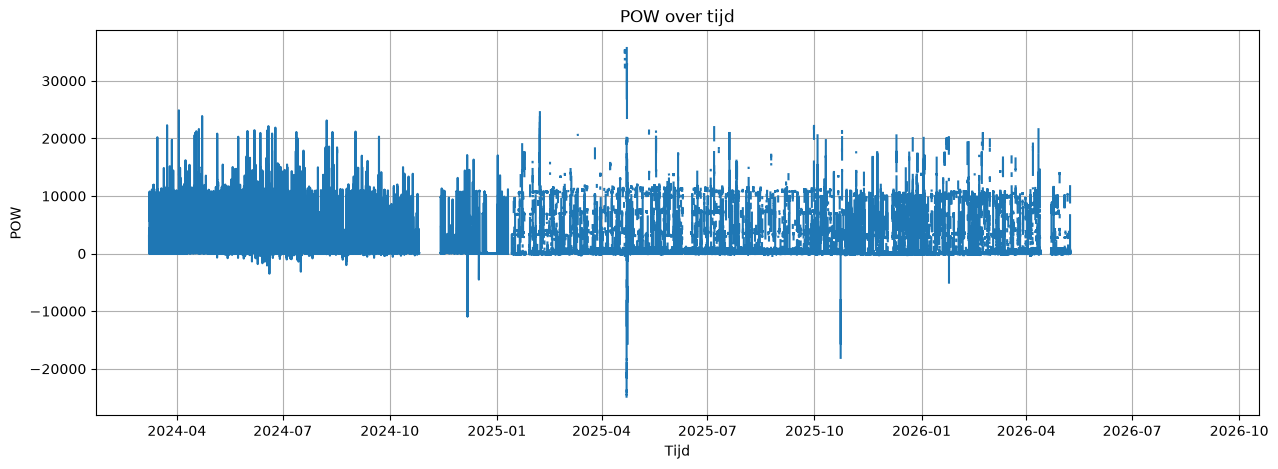

In [13]:
plt.figure(figsize=(15, 5))
plt.plot(df_totaal["timestamp"], df_totaal["POW"])

plt.xlabel("Tijd")
plt.ylabel("POW")
plt.title("POW over tijd")
plt.grid()
plt.show()

5. Begin en einde van de meetreeks, en de laatste geldige POW

In [14]:
print("Eerste timestamp:", df_totaal["timestamp"].min())
print("Laatste timestamp:", df_totaal["timestamp"].max())

#Laatste timestamp waar POW ook echt gevuld is
print("Laatste timestamp met geldige POW:", df_totaal.loc[df_totaal["POW"].notna(), "timestamp"].max())

Eerste timestamp: 2024-03-08 01:00:00+01:00
Laatste timestamp: 2026-09-07 08:05:00+02:00
Laatste timestamp met geldige POW: 2026-09-02 08:10:00+02:00


6. Controleren of er per meting meerdere POW waarden zijn

> Groeperen op timestamp + CTYPE + CTYPEC + ENAME + ETYPE

In [15]:
#Alleen rijen waar POW aanwezig is
df_carport_pow = df_carport[df_carport["POW"].notna()].copy()

In [16]:
#Per combinatie tellen hoeveel POW waarden er zijn
controle_pow = (df_carport_pow.groupby(["timestamp", "CTYPE", "CTYPEC", "ENAME", "ETYPE"], dropna=False)
    .agg(
        aantal_rijen=("POW", "size"),
        aantal_unieke_POW=("POW", "nunique"),
        min_POW=("POW", "min"),
        max_POW=("POW", "max")
    )
    .reset_index()
)

#Alleen combinaties met meer dan 1 POW waarde
controle_pow = controle_pow[controle_pow["aantal_rijen"] > 1]

controle_pow.head(50)

,timestamp,CTYPE,CTYPEC,ENAME,ETYPE,aantal_rijen,aantal_unieke_POW,min_POW,max_POW
468204,2024-10-05 20:10:00+02:00,electricity,consumption,totaalverbruik-e4393cd3dfdb,powermeter,2,2,3646.764706,4056.000000
468205,2024-10-05 20:10:00+02:00,electricity,generation,zonnepanelen-e4393cd3dfdb,solarpanel,2,2,-7242.800000,-23.500000
468206,2024-10-05 20:10:00+02:00,electricity,supply,hoofdaansluiting-e4393cd3dfdb,powermeter,2,2,927.071429,4033.400000
468207,2024-10-05 20:10:00+02:00,electricity,NaN,laadpaal1-e4393cd3dfdb,evcharger,2,2,3979.625000,4082.363636
468208,2024-10-05 20:10:00+02:00,electricity,NaN,laadpaal2-e4393cd3dfdb,evcharger,2,2,0.000250,0.000313
468209,2024-10-05 20:10:00+02:00,electricity,NaN,laadpaal3-e4393cd3dfdb,evcharger,2,2,0.000340,0.000389
468212,2024-10-05 20:10:00+02:00,electricity,NaN,overigverbruik-e4393cd3dfdb,powermeter,2,2,-26.057143,-11.382022
468213,2024-10-05 20:10:00+02:00,electricity,NaN,wijktotaalverbruik-e4393cd3dfdb,powermeter,2,2,9630.992593,10295.836735
468214,2024-10-05 20:10:00+02:00,electricity,NaN,wijktotaleopwek-e4393cd3dfdb,powermeter,2,2,-12257.200000,-23.500000
468215,2024-10-05 20:10:00+02:00,electricity,NaN,wijkvirtuelehoofdmeter-e4393cd3dfdb,powermeter,2,2,9157.367647,10230.265306


In [17]:
#Alleen rijen waar POW aanwezig is
df_pow = df_carport[df_carport["POW"].notna()].copy()

#Zoektype van Pieter
filter = ["timestamp", "CTYPE", "CTYPEC", "ENAME", "ETYPE"]

dubbel = df_pow.duplicated(subset=filter,keep=False)

dubbele_pow = (df_pow.loc[dubbel].sort_values(filter))

dubbele_pow

,timestamp,CO2EQ,CTYPE,ENAME,ETYPE,source_zip,source_csv,source_folder,CTYPEC,ESTYPE,...,ENE,POW,CO2,CO2_EXP,CO2_IMP,ENE_EXP,ENE_IMP,ENE_CNT_EXP,ENE_CNT_IMP,PRICE
527103,2024-10-05 20:10:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,NaN,3646.764706,160.393819,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527104,2024-10-05 20:10:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,336.961806,4056.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527111,2024-10-05 20:10:00+02:00,NaN,electricity,zonnepanelen-e4393cd3dfdb,solarpanel,241005_zonnepanelen-e4393cd3dfdb_c5163d01ee033...,241005_zonnepanelen-e4393cd3dfdb_c5163d01ee033...,zonnepanelen-e4393cd3dfdb,generation,NaN,...,NaN,-7242.800000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527112,2024-10-05 20:10:00+02:00,NaN,electricity,zonnepanelen-e4393cd3dfdb,solarpanel,241005_zonnepanelen-e4393cd3dfdb_c5163d01ee033...,241005_zonnepanelen-e4393cd3dfdb_c5163d01ee033...,zonnepanelen-e4393cd3dfdb,generation,NaN,...,-1.972222,-23.500000,-0.948639,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527091,2024-10-05 20:10:00+02:00,NaN,electricity,hoofdaansluiting-e4393cd3dfdb,powermeter,241005_hoofdaansluiting-e4393cd3dfdb_182475cc0...,241005_hoofdaansluiting-e4393cd3dfdb_182475cc0...,hoofdaansluiting-e4393cd3dfdb,supply,NaN,...,NaN,927.071429,159.422222,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527092,2024-10-05 20:10:00+02:00,NaN,electricity,hoofdaansluiting-e4393cd3dfdb,powermeter,241005_hoofdaansluiting-e4393cd3dfdb_182475cc0...,241005_hoofdaansluiting-e4393cd3dfdb_182475cc0...,hoofdaansluiting-e4393cd3dfdb,supply,NaN,...,334.920635,4033.400000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527093,2024-10-05 20:10:00+02:00,NaN,electricity,laadpaal1-e4393cd3dfdb,evcharger,241005_laadpaal1-e4393cd3dfdb_8f02b76d3db51938...,241005_laadpaal1-e4393cd3dfdb_8f02b76d3db51938...,laadpaal1-e4393cd3dfdb,NaN,NaN,...,NaN,3979.625000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527094,2024-10-05 20:10:00+02:00,NaN,electricity,laadpaal1-e4393cd3dfdb,evcharger,241005_laadpaal1-e4393cd3dfdb_8f02b76d3db51938...,241005_laadpaal1-e4393cd3dfdb_8f02b76d3db51938...,laadpaal1-e4393cd3dfdb,NaN,NaN,...,338.763186,4082.363636,162.945092,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527095,2024-10-05 20:10:00+02:00,NaN,electricity,laadpaal2-e4393cd3dfdb,evcharger,241005_laadpaal2-e4393cd3dfdb_8f02b76d3db51938...,241005_laadpaal2-e4393cd3dfdb_8f02b76d3db51938...,laadpaal2-e4393cd3dfdb,NaN,NaN,...,NaN,0.000313,0.000014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527096,2024-10-05 20:10:00+02:00,NaN,electricity,laadpaal2-e4393cd3dfdb,evcharger,241005_laadpaal2-e4393cd3dfdb_8f02b76d3db51938...,241005_laadpaal2-e4393cd3dfdb_8f02b76d3db51938...,laadpaal2-e4393cd3dfdb,NaN,NaN,...,0.000029,0.000250,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:
df_carport["CTYPE"].unique()

<ArrowStringArray>
['electricity']
Length: 1, dtype: str

In [19]:
df_carport["CTYPEC"].unique()

<ArrowStringArray>
['supply', nan, 'consumption', 'generation', 'storage']
Length: 5, dtype: str

### ENAME
___
1. Kijken naar alle ENAME variabelen

> Laadpaal 1-5 + Tesla & Bus
>
> Overig gebruik [Gereedschap, lampen?]
>
> Accu
>
> Zonnepanelen
>
> Hoofdaansluiting
>
> Totaalverbruik
>
> Wijktotaalverbruik
>
> Wijktotaalopwekking
>
> Voorspellingen (Totaalverbruik, Zonnepanelen)
>
> Samengevoegde colommen (Price + energie) (Odect + Price) (Price + energie wijk) (Co2 + energie)

In [20]:
df_carport["ENAME"].unique()

<ArrowStringArray>
[      'hoofdaansluiting-e4393cd3dfdb',              'laadpaal1-e4393cd3dfdb',
              'laadpaal2-e4393cd3dfdb',              'laadpaal3-e4393cd3dfdb',
         'overigverbruik-e4393cd3dfdb',         'totaalverbruik-e4393cd3dfdb',
           'zonnepanelen-e4393cd3dfdb',            'laadpaalbus-e4393cd3dfdb',
          'laadpaaltesla-e4393cd3dfdb',     'wijktotaalverbruik-e4393cd3dfdb',
        'wijktotaleopwek-e4393cd3dfdb', 'wijkvirtuelehoofdmeter-e4393cd3dfdb',
                     'co2ele_combined',               'odectprice_c911efafaa',
                 'priceele_c911efafaa',            'victronaccu-e4393cd3dfdb',
   'forec-totaalverbruik-e4393cd3dfdb',     'forec-zonnepanelen-e4393cd3dfdb',
              'laadpaal4-e4393cd3dfdb',              'laadpaal5-e4393cd3dfdb',
                     'priceele_123456']
Length: 21, dtype: str

In [21]:
Co2ele = df_carport[df_carport["ENAME"] == "co2ele_combined"]
Co2ele

,timestamp,CO2EQ,CTYPE,ENAME,ETYPE,source_zip,source_csv,source_folder,CTYPEC,ESTYPE,...,ENE,POW,CO2,CO2_EXP,CO2_IMP,ENE_EXP,ENE_IMP,ENE_CNT_EXP,ENE_CNT_IMP,PRICE
91871,2024-04-10 17:05:00+02:00,75.0,electricity,co2ele_combined,co2equivalent,240410_co2ele_c911efafaa_0a79eee450b18e6a6a697...,240410_co2ele_c911efafaa_0a79eee450b18e6a6a697...,co2ele_c911efafaa,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
91872,2024-04-10 17:10:00+02:00,75.0,electricity,co2ele_combined,co2equivalent,240410_co2ele_c911efafaa_0a79eee450b18e6a6a697...,240410_co2ele_c911efafaa_0a79eee450b18e6a6a697...,co2ele_c911efafaa,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
91873,2024-04-10 17:15:00+02:00,75.0,electricity,co2ele_combined,co2equivalent,240410_co2ele_c911efafaa_0a79eee450b18e6a6a697...,240410_co2ele_c911efafaa_0a79eee450b18e6a6a697...,co2ele_c911efafaa,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
91874,2024-04-10 17:20:00+02:00,75.0,electricity,co2ele_combined,co2equivalent,240410_co2ele_c911efafaa_0a79eee450b18e6a6a697...,240410_co2ele_c911efafaa_0a79eee450b18e6a6a697...,co2ele_c911efafaa,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
91875,2024-04-10 17:25:00+02:00,75.0,electricity,co2ele_combined,co2equivalent,240410_co2ele_c911efafaa_0a79eee450b18e6a6a697...,240410_co2ele_c911efafaa_0a79eee450b18e6a6a697...,co2ele_c911efafaa,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4818882,2026-06-20 03:35:00+02:00,204.0,electricity,co2ele_combined,co2equivalent,260620_co2ele_c911efafaa_5e73e5d7eb98144abcb1f...,260620_co2ele_c911efafaa_5e73e5d7eb98144abcb1f...,co2ele_c911efafaa,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4818914,2026-06-20 03:40:00+02:00,204.0,electricity,co2ele_combined,co2equivalent,260620_co2ele_c911efafaa_5e73e5d7eb98144abcb1f...,260620_co2ele_c911efafaa_5e73e5d7eb98144abcb1f...,co2ele_c911efafaa,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4818946,2026-06-20 03:45:00+02:00,204.0,electricity,co2ele_combined,co2equivalent,260620_co2ele_c911efafaa_5e73e5d7eb98144abcb1f...,260620_co2ele_c911efafaa_5e73e5d7eb98144abcb1f...,co2ele_c911efafaa,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4818978,2026-06-20 03:50:00+02:00,204.0,electricity,co2ele_combined,co2equivalent,260620_co2ele_c911efafaa_5e73e5d7eb98144abcb1f...,260620_co2ele_c911efafaa_5e73e5d7eb98144abcb1f...,co2ele_c911efafaa,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


2. De niet nutige Enames droppen

In [22]:
drop_values = ["co2ele_combined", "odectprice_c911efafaa", "priceele_123456", "priceele_c911efafaa", "forec-zonnepanelen-e4393cd3dfdb", "forec-totaalverbruik-e4393cd3dfdb"]

df_carport = df_carport[~df_carport["ENAME"].isin(drop_values)]


In [23]:
kolommen = [
    "timestamp",
    "CTYPE",
    "CTYPEC",
    "ENAME",
    "ETYPE",
    "POW"
]

dubbele_pow[kolommen].head(50)

,timestamp,CTYPE,CTYPEC,ENAME,ETYPE,POW
527103,2024-10-05 20:10:00+02:00,electricity,consumption,totaalverbruik-e4393cd3dfdb,powermeter,3646.764706
527104,2024-10-05 20:10:00+02:00,electricity,consumption,totaalverbruik-e4393cd3dfdb,powermeter,4056.000000
527111,2024-10-05 20:10:00+02:00,electricity,generation,zonnepanelen-e4393cd3dfdb,solarpanel,-7242.800000
527112,2024-10-05 20:10:00+02:00,electricity,generation,zonnepanelen-e4393cd3dfdb,solarpanel,-23.500000
527091,2024-10-05 20:10:00+02:00,electricity,supply,hoofdaansluiting-e4393cd3dfdb,powermeter,927.071429
527092,2024-10-05 20:10:00+02:00,electricity,supply,hoofdaansluiting-e4393cd3dfdb,powermeter,4033.400000
527093,2024-10-05 20:10:00+02:00,electricity,NaN,laadpaal1-e4393cd3dfdb,evcharger,3979.625000
527094,2024-10-05 20:10:00+02:00,electricity,NaN,laadpaal1-e4393cd3dfdb,evcharger,4082.363636
527095,2024-10-05 20:10:00+02:00,electricity,NaN,laadpaal2-e4393cd3dfdb,evcharger,0.000313
527096,2024-10-05 20:10:00+02:00,electricity,NaN,laadpaal2-e4393cd3dfdb,evcharger,0.000250


3. Geef de kolommen bruikbare namen

In [24]:
# Source - https://stackoverflow.com/a/11354850
# Posted by lexual, modified by community. See post 'Timeline' for change history
# Retrieved 2026-10-01, License - CC BY-SA 4.0

dubbele_pow.rename(columns={'CTYPE': 'electricity',
                   'CTYPEC': 'energie_types',
                   'ENAME': 'apparaat',
                   'ETYPE': 'apparaat_type',
                   'POW': 'energie'
                   }, inplace=True)

### Verdeling ENAME en ETYPE
___
1. Aantal rijen per ENAME in een grafiek

> De niet nuttige ENAMEs zijn hierboven al gedropt, dus dit is de verdeling van de overgebleven apparaten
>
> De code `-e4393cd3dfdb` achter elke naam wordt weggehaald zodat de grafiek leesbaar blijft

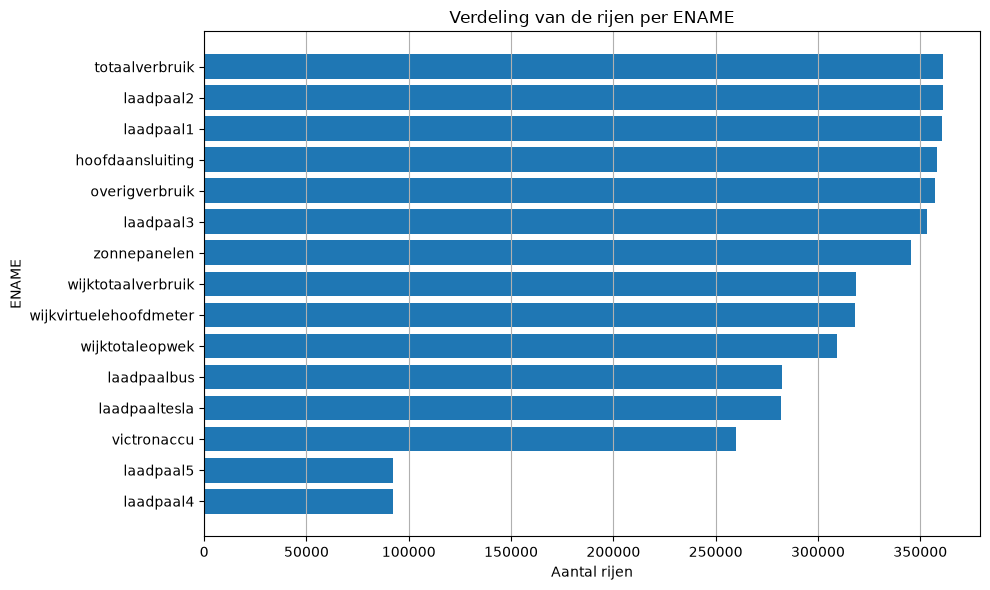

In [25]:
#Aantal rijen per ENAME, zonder de code achter de naam
ename_telling = (df_carport["ENAME"].str.replace("-e4393cd3dfdb", "").value_counts().sort_values())

plt.figure(figsize=(10, 6))
plt.barh(ename_telling.index, ename_telling.values)

plt.xlabel("Aantal rijen")
plt.ylabel("ENAME")
plt.title("Verdeling van de rijen per ENAME")
plt.grid(axis="x")
plt.tight_layout()
plt.show()

### ETYPE
___
1. Welke ETYPEs er zijn en hoe vaak ze voorkomen, ook als percentage

In [26]:
etype_overzicht = pd.DataFrame({
    "aantal_rijen": df_carport["ETYPE"].value_counts(),
    "percentage": (df_carport["ETYPE"].value_counts(normalize=True) * 100).round(2)
})

etype_overzicht

,aantal_rijen,percentage
ETYPE,,
powermeter,2025271,45.50
evcharger,1823195,40.96
solarpanel,345473,7.76
battery,256791,5.77


2. Aantal rijen per ETYPE in een grafiek

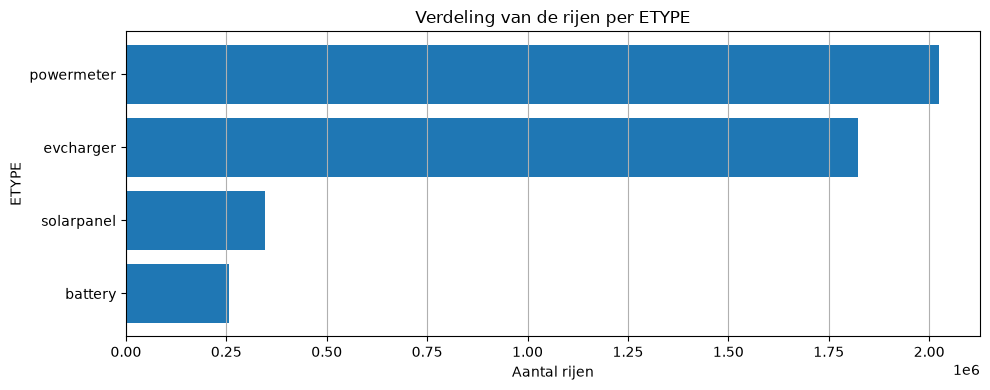

In [27]:
etype_telling = df_carport["ETYPE"].value_counts().sort_values()

plt.figure(figsize=(10, 4))
plt.barh(etype_telling.index, etype_telling.values)

plt.xlabel("Aantal rijen")
plt.ylabel("ETYPE")
plt.title("Verdeling van de rijen per ETYPE")
plt.grid(axis="x")
plt.tight_layout()
plt.show()

3. Welke ENAMEs bij welk ETYPE horen

> Hiermee is te zien welke apparaten onder hetzelfde type vallen (bv. alle laadpalen onder evcharger)

In [28]:
#Kruistabel van ENAME tegenover ETYPE
ename_per_etype = pd.crosstab(df_carport["ENAME"].str.replace("-e4393cd3dfdb", ""), df_carport["ETYPE"])

ename_per_etype

ETYPE,battery,evcharger,powermeter,solarpanel
ENAME,,,,
hoofdaansluiting,0,0,358041,0
laadpaal1,0,360517,0,0
laadpaal2,0,360889,0,0
laadpaal3,0,353343,0,0
laadpaal4,0,92220,0,0
laadpaal5,0,92220,0,0
laadpaalbus,0,282308,0,0
laadpaaltesla,0,281698,0,0
overigverbruik,0,0,356967,0


4. Welke kolommen per ETYPE gevuld zijn, als percentage

> Kolommen die bij een ETYPE (bijna) altijd leeg zijn worden niet gemeten voor dat type

In [29]:
#Percentage ingevulde waarden per kolom, per ETYPE
gevuld_per_etype = (df_carport.drop(columns=["source_zip", "source_csv", "source_folder"])
                    .groupby("ETYPE").agg(lambda kolom: kolom.notna().mean() * 100).round(1)
)

gevuld_per_etype.T

ETYPE,battery,evcharger,powermeter,solarpanel
timestamp,100.0,100.0,100.0,100.0
CO2EQ,0.0,0.0,0.0,0.0
CTYPE,100.0,100.0,100.0,100.0
ENAME,100.0,100.0,100.0,100.0
CTYPEC,50.9,41.9,48.8,60.0
ESTYPE,0.0,0.0,0.0,0.0
forecast.ENE,0.0,0.0,0.0,0.0
forecast.POW,0.0,0.0,0.0,0.0
ENE,50.3,54.6,58.9,58.8
POW,45.8,45.3,54.4,52.2


5. Statistiek van POW per ETYPE

> Negatieve POW betekent teruglevering (zoals bij de zonnepanelen)

In [30]:
pow_per_etype = df_carport.groupby("ETYPE")["POW"].describe()

pow_per_etype

,count,mean,std,min,25%,50%,75%,max
ETYPE,,,,,,,,
battery,117627.0,3.997454e+02,6.876758e+03,-3.536584e+04,-1529.863376,95.941176,393.292560,3.263411e+04
evcharger,826768.0,4.271920e+02,1.819004e+03,-2.000000e+00,0.000000,0.000000,0.000298,1.146183e+04
powermeter,1102551.0,4.764827e+13,1.925892e+18,-1.403426e+21,-155.455844,86.125000,3472.206171,1.455960e+21
solarpanel,180223.0,-8.050830e+03,1.236975e+04,-6.333825e+04,-11723.158288,-1011.304348,-23.500000,7.237143e+01


6. Spreiding van POW per ETYPE in een boxplot

> Uitschieters worden niet getoond zodat de boxen zichtbaar blijven

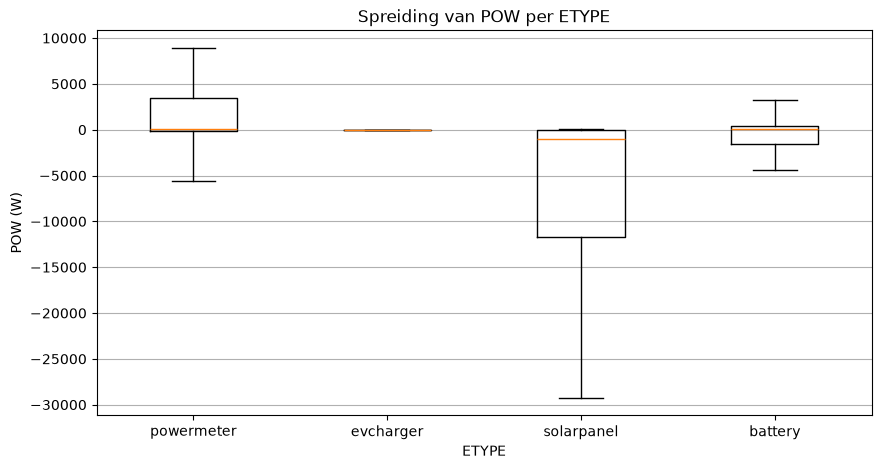

In [31]:
#Per ETYPE de geldige POW waarden verzamelen
etypes = df_carport["ETYPE"].dropna().unique()
pow_waarden = [df_carport.loc[(df_carport["ETYPE"] == etype) & df_carport["POW"].notna(), "POW"] for etype in etypes]

plt.figure(figsize=(10, 5))
plt.boxplot(pow_waarden, tick_labels=etypes, showfliers=False)

plt.xlabel("ETYPE")
plt.ylabel("POW (W)")
plt.title("Spreiding van POW per ETYPE")
plt.grid(axis="y")
plt.show()

7. Periode waarin elk ETYPE gemeten is

In [32]:
periode_per_etype = (df_carport.groupby("ETYPE").agg(
        eerste_meting=("timestamp", "min"),
        laatste_meting=("timestamp", "max"),
        aantal_enames=("ENAME", "nunique")
    )
)

periode_per_etype

,eerste_meting,laatste_meting,aantal_enames
ETYPE,,,
battery,2025-02-25 14:15:00+01:00,2026-09-07 08:05:00+02:00,1
evcharger,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,7
powermeter,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,7
solarpanel,2024-03-08 01:05:00+01:00,2026-09-07 08:05:00+02:00,1


### Dubbele metingen samenvoegen
___
Bij veel timestamps staat dezelfde meting van hetzelfde apparaat in meer dan één rij. Eerder in dit notebook werden die rijen samengevoegd met het gemiddelde. Dat mag alleen als de rijen elkaar **aanvullen**, niet als ze elkaar **tegenspreken**:

> **Aanvullend** (mag samengevoegd worden): rij 1 heeft POW = 500 en ENE leeg, rij 2 heeft POW leeg en ENE = 0,8. De rest is hetzelfde. Samen vormen ze één complete meting
>
> **Tegenstrijdig** (mag niet gemiddeld worden): rij 1 heeft POW = 100 en rij 2 heeft POW = 500. Het gemiddelde (300) is nooit gemeten, dus dat zou een verzonnen waarde zijn

De regel die we gebruiken: alle rijen met dezelfde timestamp en hetzelfde apparaat (ENAME) worden één rij. Per kolom geldt:
* Er is één ingevulde waarde → die waarde wordt overgenomen
* Er zijn twee verschillende ingevulde waarden → we weten niet welke klopt, dus de waarde wordt leeg gemaakt. Lege waarden worden verderop in de sectie *Missende waarden* onderbouwd ingevuld

1. Rijen met een dubbele combinatie van timestamp en ENAME apart zetten

*Dit is alleen gedaan voor exploratie, in [06_Dataprep.ipynb](./06_Dataprep.ipynb) staat de correcte imputer voor het model*

In [33]:
SLEUTEL = ["timestamp", "ENAME"]

#Kolommen met meetwaarden (getallen)
MEET_KOLOMMEN = df_carport.select_dtypes("number").columns.tolist()

#Kolommen die de context van de meting beschrijven
CONTEXT_KOLOMMEN = ["CTYPE", "CTYPEC", "ETYPE"]

#True als de combinatie van timestamp en ENAME vaker voorkomt
is_dubbel = df_carport.duplicated(SLEUTEL, keep=False)

df_uniek = df_carport[~is_dubbel]
df_dubbel_alle = df_carport[is_dubbel]

print("Rijen die al uniek zijn:", len(df_uniek))
print("Rijen met een dubbele timestamp + ENAME:", len(df_dubbel_alle))
print("Aantal groepen dubbele rijen:", df_dubbel_alle.groupby(SLEUTEL).ngroups)

Rijen die al uniek zijn: 749179
Rijen met een dubbele timestamp + ENAME: 3701551
Aantal groepen dubbele rijen: 1849337


2. Per groep en per kolom kijken of de rijen elkaar tegenspreken

> Meetwaarden: als de hoogste en laagste ingevulde waarde in de groep verschillen, zijn er twee verschillende waarden
>
> Context (CTYPE, CTYPEC, ETYPE): als er meer dan één verschillende ingevulde waarde is. Een lege CTYPEC naast "consumption" is dus géén tegenstrijdigheid, maar een aanvulling

In [34]:
groepen = df_dubbel_alle.groupby(SLEUTEL)

#True als een meetwaarde in de groep twee verschillende waarden heeft (lege waarden tellen niet mee)
meet_conflict = (groepen[MEET_KOLOMMEN].max() - groepen[MEET_KOLOMMEN].min()) > 0

#True als de context in de groep twee verschillende waarden heeft
context_conflict = groepen[CONTEXT_KOLOMMEN].nunique() > 1

#Elke groep een soort geven
groep_soort = pd.Series("aanvullend", index=meet_conflict.index)
groep_soort[meet_conflict.any(axis=1)] = "tegenstrijdig (meetwaarde)"
groep_soort[context_conflict.any(axis=1)] = "tegenstrijdig (context)"

groep_soort.value_counts()

aanvullend                    1847888
tegenstrijdig (context)          1439
tegenstrijdig (meetwaarde)         10
Name: count, dtype: int64

3. In welke kolommen en bij welke apparaten de tegenstrijdigheden zitten

In [35]:
#Aantal groepen met een tegenstrijdigheid per kolom (alleen kolommen waar het voorkomt)
conflict_per_kolom = pd.concat([meet_conflict, context_conflict], axis=1).sum()
conflict_per_kolom[conflict_per_kolom > 0].sort_values(ascending=False)

ETYPE          1439
ENE_CNT_IMP    1429
ENE_CNT_EXP    1422
ENE             264
CO2             264
CO2_IMP         181
ENE_IMP         181
ENE_EXP         103
CO2_EXP         103
POW              11
dtype: int64

In [36]:
#Aantal tegenstrijdige POW waarden per apparaat
pow_conflict_per_apparaat = meet_conflict["POW"].groupby(level="ENAME").sum()
pow_conflict_per_apparaat[pow_conflict_per_apparaat > 0].sort_values(ascending=False)

ENAME
hoofdaansluiting-e4393cd3dfdb          1
laadpaal1-e4393cd3dfdb                 1
laadpaal2-e4393cd3dfdb                 1
laadpaal3-e4393cd3dfdb                 1
overigverbruik-e4393cd3dfdb            1
totaalverbruik-e4393cd3dfdb            1
victronaccu-e4393cd3dfdb               1
wijktotaalverbruik-e4393cd3dfdb        1
wijktotaleopwek-e4393cd3dfdb           1
wijkvirtuelehoofdmeter-e4393cd3dfdb    1
zonnepanelen-e4393cd3dfdb              1
Name: POW, dtype: int64

4. Een voorbeeld van elke soort bekijken

In [37]:
TOON = ["timestamp", "ENAME", "CTYPEC", "ETYPE", "POW", "ENE", "source_zip"]

for soort in groep_soort.unique():
    timestamp, ename = groep_soort[groep_soort == soort].index[0]
    print(soort)
    display(df_dubbel_alle.loc[(df_dubbel_alle["timestamp"] == timestamp) & (df_dubbel_alle["ENAME"] == ename), TOON])

tegenstrijdig (meetwaarde)


,timestamp,ENAME,CTYPEC,ETYPE,POW,ENE,source_zip
527091,2024-10-05 20:10:00+02:00,hoofdaansluiting-e4393cd3dfdb,supply,powermeter,927.071429,NaN,241005_hoofdaansluiting-e4393cd3dfdb_182475cc0...
527092,2024-10-05 20:10:00+02:00,hoofdaansluiting-e4393cd3dfdb,supply,powermeter,4033.400000,334.920635,241005_hoofdaansluiting-e4393cd3dfdb_182475cc0...


aanvullend


,timestamp,ENAME,CTYPEC,ETYPE,POW,ENE,source_zip
753334,2025-01-14 09:20:00+01:00,hoofdaansluiting-e4393cd3dfdb,NaN,powermeter,NaN,NaN,250114_hoofdaansluiting-e4393cd3dfdb_e83f16f95...
753335,2025-01-14 09:20:00+01:00,hoofdaansluiting-e4393cd3dfdb,supply,powermeter,-1481.707865,-103.455939,250114_hoofdaansluiting-e4393cd3dfdb_e83f16f95...


tegenstrijdig (context)


,timestamp,ENAME,CTYPEC,ETYPE,POW,ENE,source_zip
1081567,2025-02-25 14:15:00+01:00,victronaccu-e4393cd3dfdb,NaN,powermeter,NaN,NaN,250225_victronaccu-e4393cd3dfdb_4383e76b5948c5...
1081568,2025-02-25 14:15:00+01:00,victronaccu-e4393cd3dfdb,storage,powermeter,77.272727,0.0,250225_victronaccu-e4393cd3dfdb_4383e76b5948c5...
1081569,2025-02-25 14:15:00+01:00,victronaccu-e4393cd3dfdb,storage,battery,30.759494,NaN,250225_victronaccu-e4393cd3dfdb_4383e76b5948c5...


5. Samenvoegen

> Per kolom wordt de ingevulde waarde overgenomen (`first()` slaat lege waarden over)
>
> Tegenstrijdige meetwaarden worden daarna leeg gemaakt
>
> Bij tegenstrijdige context (alleen als stap 2 dat laat zien) wordt de eerste waarde overgenomen, zodat de meting bij het apparaat blijft horen

In [38]:
#Per groep de eerste ingevulde waarde van elke kolom
df_samengevoegd = groepen.first()

#Tegenstrijdige meetwaarden leegmaken in plaats van middelen
df_samengevoegd[MEET_KOLOMMEN] = df_samengevoegd[MEET_KOLOMMEN].mask(meet_conflict)

#Terugzetten bij de rijen die al uniek waren
df_carport = (pd.concat([df_uniek, df_samengevoegd.reset_index()], ignore_index=True)
              .sort_values(SLEUTEL).reset_index(drop=True))

print("Rijen na samenvoegen:", len(df_carport))
print("Dubbele timestamp + ENAME over:", df_carport.duplicated(SLEUTEL).sum())
print("POW waarden leeggemaakt door tegenstrijdigheid:", meet_conflict["POW"].sum())

Rijen na samenvoegen: 2598516
Dubbele timestamp + ENAME over: 0
POW waarden leeggemaakt door tegenstrijdigheid: 11


6. Conclusie

> Rijen die elkaar aanvullen zijn samengevoegd tot één complete meting
>
> Bij tegenstrijdige waarden is **niet** gemiddeld. Die waarde is leeg gemaakt en wordt behandeld als missende waarde
>
> Vanaf hier heeft elk apparaat precies één rij per timestamp. Verderop in het notebook hoeft er dus nergens meer gemiddeld te worden

### Evcharger verbruik
___
In de statistiek per ETYPE lijkt evcharger geen verbruik te hebben, maar dat klopt niet helemaal:

> Mediaan = 0 W en 75% = 0.0003 W, dus meer dan driekwart van de metingen staat de laadpaal stil
>
> Gemiddelde = 427 W en max = 11.461 W, dus er wordt wel degelijk geladen, alleen in korte periodes
>
> Waarden als 0.0003 W zijn sensorruis / stand-by en geen echt verbruik

Daarom worden de laadmomenten hieronder apart van de stilstand bekeken.

1. Alleen de POW metingen van de laadpalen apart zetten

> Dubbele metingen zijn in de sectie hierboven al samengevoegd, dus er is per laadpaal precies één meting per timestamp

In [39]:
#Alleen evcharger rijen met een POW waarde
df_laad = df_carport[(df_carport["ETYPE"] == "evcharger") & df_carport["POW"].notna()][["timestamp", "ENAME", "POW"]].copy()

#Korte naam zonder de code erachter
df_laad["ENAME"] = df_laad["ENAME"].str.replace("-e4393cd3dfdb", "")

print("Aantal metingen:", len(df_laad))
df_laad.head()

Aantal metingen: 826762


,timestamp,ENAME,POW
1,2024-03-08 01:00:00+01:00,laadpaal1,0.000353
2,2024-03-08 01:00:00+01:00,laadpaal2,316.100317
3,2024-03-08 01:00:00+01:00,laadpaal3,0.000465
7,2024-03-08 01:05:00+01:00,laadpaal1,0.000471
8,2024-03-08 01:05:00+01:00,laadpaal2,3315.222222


2. Statistiek van POW per laadpaal

In [40]:
df_laad.groupby("ENAME")["POW"].describe()

,count,mean,std,min,25%,50%,75%,max
ENAME,,,,,,,,
laadpaal1,208992.0,247.297916,1321.748298,0.0,0.0,0.0,0.000275,11079.548387
laadpaal2,209153.0,365.890349,1463.040698,0.0,0.0,0.0,0.000318,10943.078125
laadpaal3,204467.0,294.770301,1238.576784,0.0,0.0,0.0,0.000337,10859.528000
laadpaal4,40709.0,12.904151,310.087366,0.0,0.0,0.0,0.000000,11119.310881
laadpaal5,40709.0,3.880760,167.934226,0.0,0.0,0.0,0.000000,8010.236264
laadpaalbus,60069.0,1292.200233,3471.106518,-1.0,0.0,0.0,0.416667,11216.414286
laadpaaltesla,62663.0,1378.724558,3466.991774,-2.0,0.0,0.0,1.500000,11461.826087


3. Bepalen wanneer een laadpaal aan het laden is

> Grens van 100 W: alles daaronder is ruis of stand-by

In [41]:
LAAD_GRENS = 100

#True als de laadpaal op dat moment echt aan het laden is
df_laad["laden"] = df_laad["POW"] > LAAD_GRENS

#Percentage van de metingen waarin geladen wordt, per laadpaal
laad_percentage = (df_laad.groupby("ENAME")["laden"].mean() * 100).round(2).sort_values()

laad_percentage

ENAME
laadpaal5         0.06
laadpaal4         0.51
laadpaal1         4.54
laadpaal3         6.81
laadpaal2         7.69
laadpaalbus      12.50
laadpaaltesla    15.42
Name: laden, dtype: float64

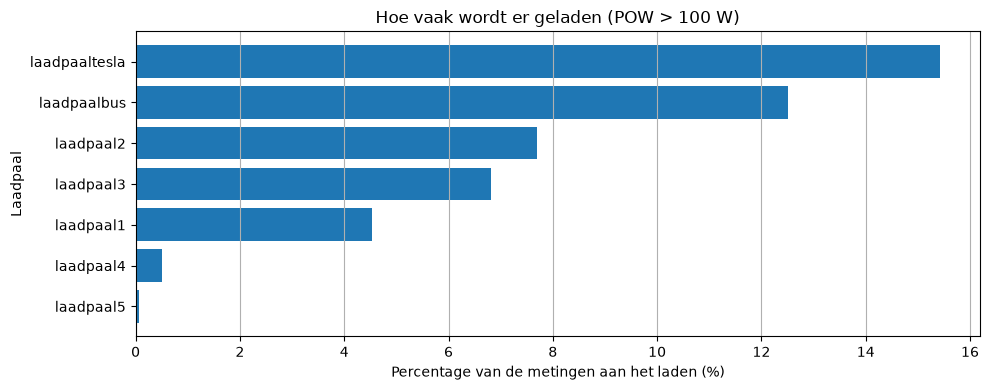

In [42]:
plt.figure(figsize=(10, 4))
plt.barh(laad_percentage.index, laad_percentage.values)

plt.xlabel("Percentage van de metingen aan het laden (%)")
plt.ylabel("Laadpaal")
plt.title(f"Hoe vaak wordt er geladen (POW > {LAAD_GRENS} W)")
plt.grid(axis="x")
plt.tight_layout()
plt.show()

4. Verdeling van het laadvermogen, alleen tijdens het laden

> Pieken rond vaste waarden (bv. ~3.7 kW, ~7.4 kW of ~11 kW) laten zien met welk vermogen de auto's laden

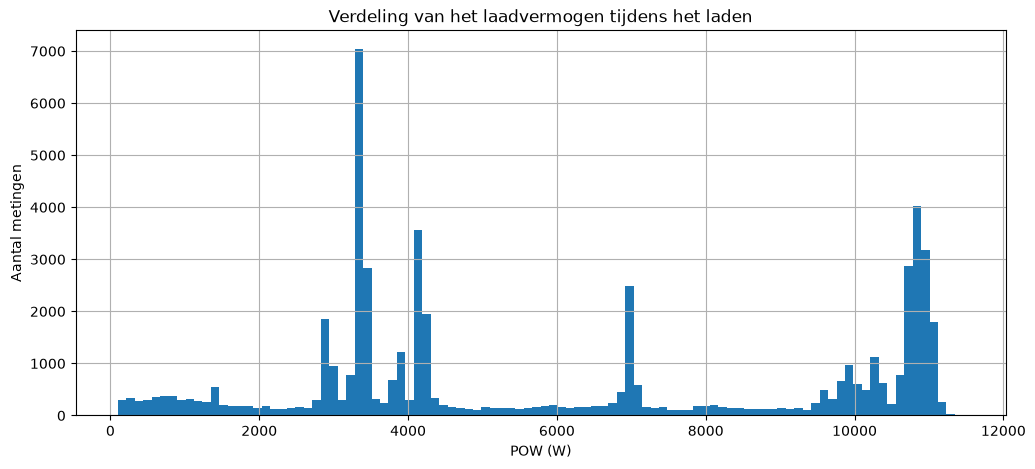

In [43]:
#Alleen de momenten waarop echt geladen wordt
df_laden = df_laad[df_laad["laden"]]

plt.figure(figsize=(12, 5))
plt.hist(df_laden["POW"], bins=100)

plt.xlabel("POW (W)")
plt.ylabel("Aantal metingen")
plt.title("Verdeling van het laadvermogen tijdens het laden")
plt.grid()
plt.show()

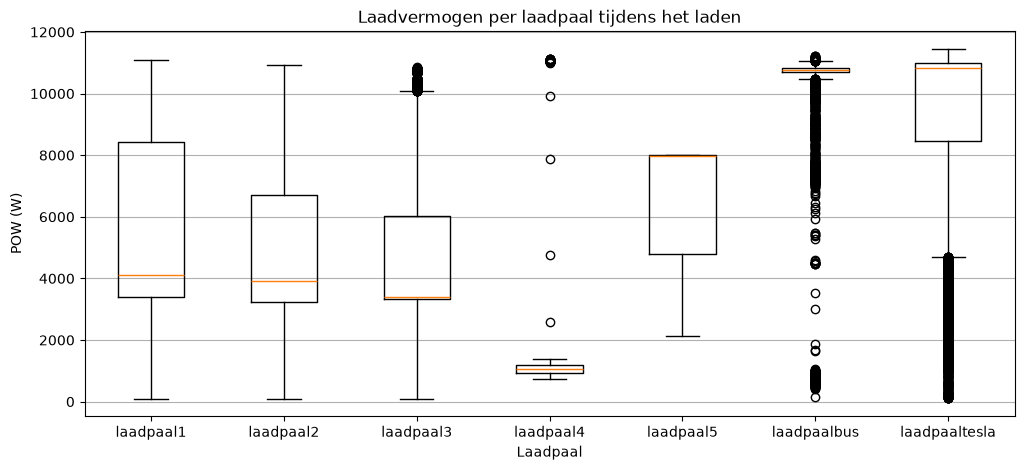

In [44]:
#Boxplot per laadpaal, alleen tijdens het laden
laadpalen = sorted(df_laden["ENAME"].unique())
pow_laden = [df_laden.loc[df_laden["ENAME"] == laadpaal, "POW"] for laadpaal in laadpalen]

plt.figure(figsize=(12, 5))
plt.boxplot(pow_laden, tick_labels=laadpalen)

plt.xlabel("Laadpaal")
plt.ylabel("POW (W)")
plt.title("Laadvermogen per laadpaal tijdens het laden")
plt.grid(axis="y")
plt.show()

5. Op welk uur van de dag wordt er geladen

> Belangrijk voor het project: laden overdag (zon) is gunstig, laden 's avonds/'s nachts haalt stroom van het net

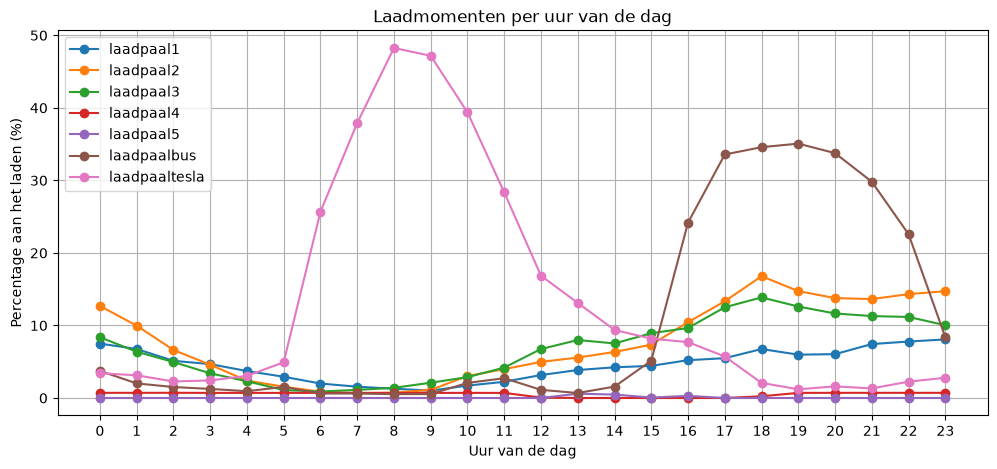

In [45]:
df_laad["uur"] = df_laad["timestamp"].dt.hour

#Percentage aan het laden per uur, per laadpaal
laden_per_uur = (df_laad.groupby(["uur", "ENAME"])["laden"].mean() * 100).unstack()

plt.figure(figsize=(12, 5))
for laadpaal in laden_per_uur.columns:
    plt.plot(laden_per_uur.index, laden_per_uur[laadpaal], marker="o", label=laadpaal)

plt.xlabel("Uur van de dag")
plt.ylabel("Percentage aan het laden (%)")
plt.title("Laadmomenten per uur van de dag")
plt.xticks(range(24))
plt.legend()
plt.grid()
plt.show()

6. Geladen energie per week, voor alle laadpalen samen

> Energie per meting (kWh) = POW (W) * 5/60 uur / 1000
>
> Weken met minder dan de helft van de metingen worden niet getoond, anders lijkt het alsof er 0 kWh geladen is terwijl de data ontbreekt (zoals vanaf mei 2026)

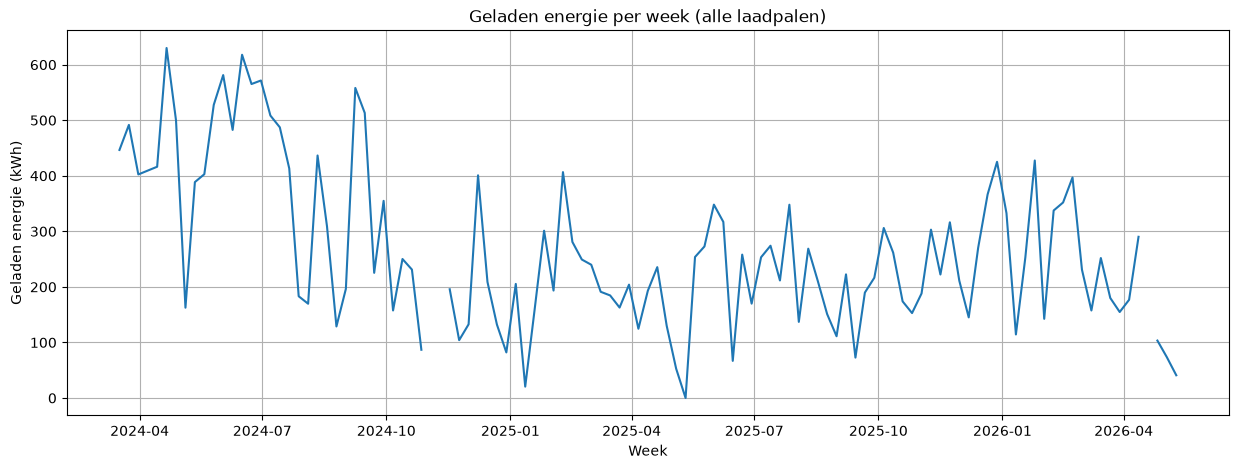

Totaal geladen (kWh): 29432
Weken zonder (genoeg) data: 21


In [46]:
#Aantal metingen in een volledige week (elke 5 minuten)
METINGEN_PER_WEEK = 7 * 24 * 12
MIN_METINGEN = METINGEN_PER_WEEK * 0.5

#Energie per meting van 5 minuten in kWh
df_laad["kWh"] = df_laad["POW"].clip(lower=0) * (5 / 60) / 1000

#Optellen per week
kwh_per_week = df_laad.set_index("timestamp")["kWh"].resample("W").sum()

#Aantal unieke timestamps per week, om weken zonder data te herkennen
metingen_per_week = df_laad.drop_duplicates("timestamp").set_index("timestamp")["kWh"].resample("W").size()

#Weken met te weinig metingen leeg maken
kwh_per_week = kwh_per_week.where(metingen_per_week >= MIN_METINGEN)

plt.figure(figsize=(15, 5))
plt.plot(kwh_per_week.index, kwh_per_week.values)

plt.xlabel("Week")
plt.ylabel("Geladen energie (kWh)")
plt.title("Geladen energie per week (alle laadpalen)")
plt.grid()
plt.show()

print("Totaal geladen (kWh):", round(df_laad["kWh"].sum()))
print("Weken zonder (genoeg) data:", kwh_per_week.isna().sum())

7. Wat de batterij per week heeft gedaan, naast het laden van de auto's

> Batterij = victronaccu, gemeten vanaf februari 2025, daarvoor is er dus geen data
>
> Aanname: positieve POW = batterij laadt op, negatieve POW = batterij levert stroom

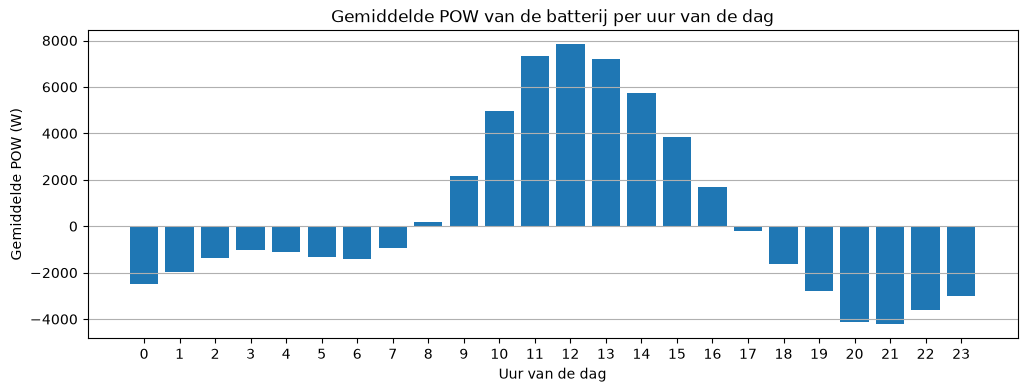

In [47]:
#Alleen de POW metingen van de batterij, met de timestamp als index
accu_pow = (df_carport[(df_carport["ENAME"] == "victronaccu-e4393cd3dfdb") & df_carport["POW"].notna()]
            .set_index("timestamp")["POW"]
)

#Gemiddelde POW per uur van de dag, om de aanname over plus en min te controleren
accu_per_uur = accu_pow.groupby(accu_pow.index.hour).mean()

plt.figure(figsize=(12, 4))
plt.bar(accu_per_uur.index, accu_per_uur.values)

plt.xlabel("Uur van de dag")
plt.ylabel("Gemiddelde POW (W)")
plt.title("Gemiddelde POW van de batterij per uur van de dag")
plt.xticks(range(24))
plt.grid(axis="y")
plt.show()

> Controle: overdag (zon) zou de POW vooral positief moeten zijn (opladen) en 's avonds negatief (stroom leveren). Is dit andersom, dan moeten laden en ontladen hieronder omgedraaid worden

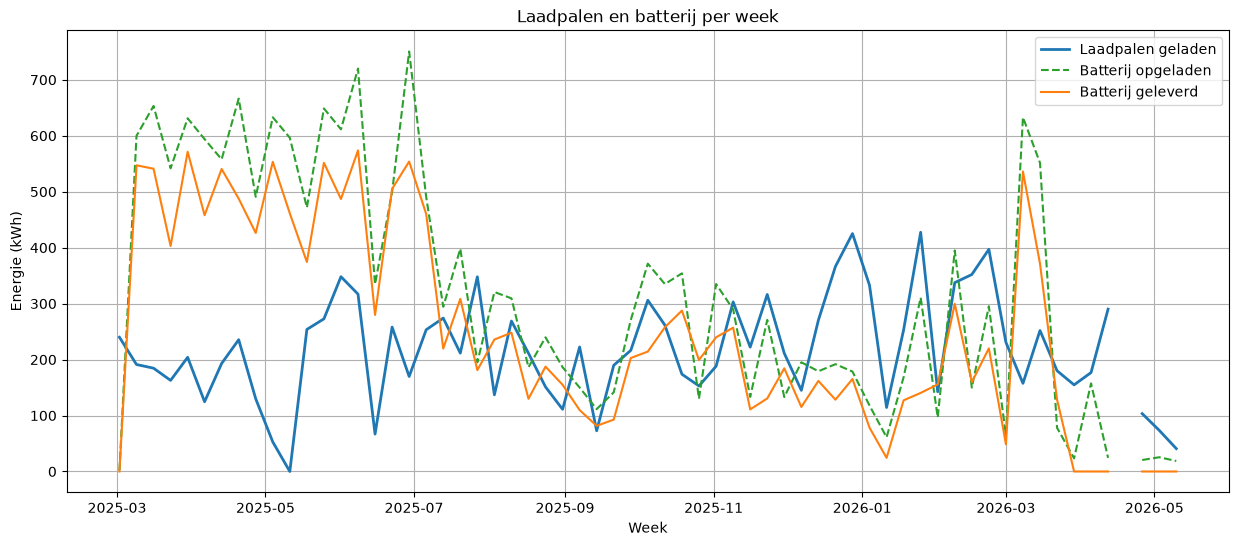

In [48]:
#Energie per meting in kWh, gesplitst in opladen en stroom leveren
accu_kwh = pd.DataFrame({
    "opgeladen": accu_pow.clip(lower=0) * (5 / 60) / 1000,
    "geleverd": accu_pow.clip(upper=0).abs() * (5 / 60) / 1000
})

#Optellen per week en weken met te weinig metingen leeg maken
accu_per_week = accu_kwh.resample("W").sum()
accu_metingen = accu_kwh.resample("W").size()
accu_per_week = accu_per_week.where(accu_metingen >= MIN_METINGEN)

#Alleen de weken waarin de batterij gemeten is, zodat beide lijnen over dezelfde periode gaan
start_accu = accu_per_week.dropna().index.min()
laad_vanaf_accu = kwh_per_week[kwh_per_week.index >= start_accu]

#Alles in een grafiek, zelfde eenheid (kWh) dus een y-as
plt.figure(figsize=(15, 6))
plt.plot(laad_vanaf_accu.index, laad_vanaf_accu.values, color="tab:blue", linewidth=2, label="Laadpalen geladen")
plt.plot(accu_per_week.index, accu_per_week["opgeladen"], color="tab:green", linestyle="--", label="Batterij opgeladen")
plt.plot(accu_per_week.index, accu_per_week["geleverd"], color="tab:orange", label="Batterij geleverd")

plt.xlabel("Week")
plt.ylabel("Energie (kWh)")
plt.title("Laadpalen en batterij per week")
plt.legend()
plt.grid()
plt.show()

# Grafiek gemaakt met hulp can Claude Opus 5.5 (Anthropic 2026)
# Promt:Ik heb deze grafiek, nu wil ik de grafiek met accu waarden erbij stoppen om te kijken of er correlatie is, zou je hier mee kunnen helpen?
# Meegestuurede bijlage: de grafiek van EVcharger 6.

> Correlatie tussen de laadpalen en de batterij per week: dicht bij 1 = ze gaan samen omhoog en omlaag, rond 0 = geen verband


In [49]:
#Alleen weken waarin beide gemeten zijn
week_vergelijking = pd.concat([kwh_per_week.rename("laadpalen"), accu_per_week], axis=1).dropna()

week_vergelijking.corr().round(2)


,laadpalen,opgeladen,geleverd
laadpalen,1.00,0.02,-0.02
opgeladen,0.02,1.00,0.97
geleverd,-0.02,0.97,1.00


> Opgeladen is altijd iets hoger dan geleverd door verlies in de batterij. Een groot verschil kan ook op ontbrekende metingen wijzen

In [50]:
#Totalen en het rendement van de batterij
print("Totaal opgeladen (kWh):", round(accu_kwh["opgeladen"].sum()))
print("Totaal geleverd (kWh):", round(accu_kwh["geleverd"].sum()))
print(f"Rendement: {accu_kwh['geleverd'].sum() / accu_kwh['opgeladen'].sum() * 100:.1f}%")

Totaal opgeladen (kWh): 19588
Totaal geleverd (kWh): 15670
Rendement: 80.0%


8. Hoeveel van het laden had door de zonnepanelen gedekt kunnen worden

> Per timestamp: laadvermogen van alle laadpalen samen tegenover de opwek van de zonnepanelen
>
> Zonnepanelen POW is negatief (opwek), daarom wordt de absolute waarde gebruikt

In [51]:
#Totaal laadvermogen per timestamp
laad_totaal = df_laad.groupby("timestamp")["POW"].sum().clip(lower=0)

#Opwek van de zonnepanelen per timestamp
zon = (df_carport[(df_carport["ENAME"] == "zonnepanelen-e4393cd3dfdb") & df_carport["POW"].notna()]
       .set_index("timestamp")["POW"].clip(upper=0).abs()
)

#Alleen timestamps waar beide gemeten zijn
laad_zon = pd.concat([laad_totaal.rename("laden"), zon.rename("zon")], axis=1, join="inner")

#Deel van het laadvermogen dat de zon tegelijk opwekt
laad_zon["gedekt"] = laad_zon[["laden", "zon"]].min(axis=1)

dekking = laad_zon["gedekt"].sum() / laad_zon["laden"].sum() * 100
print(f"Percentage van het laden dat door de zon gedekt wordt: {dekking:.1f}%")

Percentage van het laden dat door de zon gedekt wordt: 40.9%


### Onmogelijke POW waarden
___
**Wat is POW?**

POW is het vermogen in watt: hoe hard er op dat moment stroom door een apparaat of kabel loopt. Ter vergelijking:

> Een waterkoker gebruikt ongeveer 2.000 W
>
> Een laadpaal laadt een auto met maximaal ongeveer 11.000 W (11 kW) 
>
> Een gemiddeld huis gebruikt zelden meer dan 10.000 W tegelijk

- [Bron 1](https://wattever.nl/laadsnelheid-thuislaadpaal/)
- [Bron 2](https://www.anwb.nl/energie/energieverbruik/4-personen)

**Wat is het probleem?**

In de statistiek per ETYPE staat bij powermeter een maximum van 1,4·10²¹ W. Dat is een 1 met 21 nullen. Alle elektriciteitscentrales op aarde samen leveren ongeveer 9·10¹² W, dus deze meting is meer dan 100 miljoen keer zoveel als de hele wereld kan opwekken. Zulke waarden zijn **onmogelijk** en komen door een fout in de meter of bij het opslaan van de data, niet door echt verbruik.

Eén zo'n waarde maakt het gemiddelde en elke grafiek onbruikbaar, en een voorspellingsmodel zou er volledig door in de war raken. Daarom worden ze hieronder opgespoord en weggehaald.

1. Per apparaat de laagste en hoogste POW waarde bekijken

In [52]:
#Korte naam zonder de code erachter
df_carport["apparaat_kort"] = df_carport["ENAME"].str.replace("-e4393cd3dfdb", "")

#Laagste en hoogste POW per apparaat
pow_bereik = df_carport.groupby("apparaat_kort")["POW"].agg(["min", "max", "count"])

pow_bereik

,min,max,count
apparaat_kort,,,
hoofdaansluiting,-6.213176e+04,2.968922e+04,203708
laadpaal1,0.000000e+00,1.107955e+04,208992
laadpaal2,0.000000e+00,1.094308e+04,209153
laadpaal3,0.000000e+00,1.085953e+04,204467
laadpaal4,0.000000e+00,1.111931e+04,40709
laadpaal5,0.000000e+00,8.010236e+03,40709
laadpaalbus,-1.000000e+00,1.121641e+04,60069
laadpaaltesla,-2.000000e+00,1.146183e+04,62663
overigverbruik,-3.208346e+04,3.538375e+04,205075


2. Een grens kiezen voor wat fysiek mogelijk is

> De carport heeft één aansluiting op het net. Die kan maar een beperkte hoeveelheid stroom leveren, ruim onder de 100.000 W (100 kW)
>
> Alles boven de 100 kW of onder de -100 kW kan dus nooit echt gemeten zijn


In [53]:
#Grens in watt, alles daarbuiten is onmogelijk
MAX_VERMOGEN = 100_000

#True als de POW waarde buiten de grens valt
onmogelijk = df_carport["POW"].abs() > MAX_VERMOGEN

print("Aantal onmogelijke POW waarden:", onmogelijk.sum())
print(f"Percentage van alle POW waarden: {onmogelijk.sum() / df_carport['POW'].notna().sum() * 100:.4f}%")

Aantal onmogelijke POW waarden: 15
Percentage van alle POW waarden: 0.0007%


3. Bij welke apparaten de onmogelijke waarden voorkomen

In [54]:
#Aantal onmogelijke waarden per apparaat
onmogelijk_per_apparaat = df_carport[onmogelijk].groupby("apparaat_kort").size().sort_values(ascending=False)

onmogelijk_per_apparaat

apparaat_kort
wijktotaleopwek           10
wijkvirtuelehoofdmeter     4
wijktotaalverbruik         1
dtype: int64

4. Wanneer de onmogelijke waarden voorkomen

> Als ze allemaal op een paar dagen vallen, wijst dat op een storing of een moment waarop de meter is vervangen of opnieuw gestart

In [55]:
#Alleen de onmogelijke rijen, met de belangrijkste kolommen
df_onmogelijk = df_carport.loc[onmogelijk, ["timestamp", "apparaat_kort", "ETYPE", "POW"]].sort_values("timestamp")

#Aantal onmogelijke waarden per dag
onmogelijk_per_dag = df_onmogelijk.groupby(df_onmogelijk["timestamp"].dt.date).size()

print("Aantal dagen met onmogelijke waarden:", len(onmogelijk_per_dag))
onmogelijk_per_dag.sort_values(ascending=False).head(10)

Aantal dagen met onmogelijke waarden: 4


timestamp
2026-05-08    9
2026-05-07    3
2025-09-24    2
2026-03-26    1
dtype: int64

In [56]:
df_onmogelijk.head(20)

,timestamp,apparaat_kort,ETYPE,POW
1593938,2025-09-24 09:50:00+02:00,wijktotaalverbruik,powermeter,-1.403426e+21
1593939,2025-09-24 09:50:00+02:00,wijktotaleopwek,powermeter,1.455960e+21
2341607,2026-03-26 11:35:00+01:00,wijktotaleopwek,powermeter,-1.012922e+05
2482703,2026-05-07 12:40:00+02:00,wijktotaleopwek,powermeter,-1.020519e+05
2482704,2026-05-07 12:40:00+02:00,wijkvirtuelehoofdmeter,powermeter,-1.017000e+05
2482793,2026-05-07 13:10:00+02:00,wijktotaleopwek,powermeter,-1.045165e+05
2487023,2026-05-08 12:40:00+02:00,wijktotaleopwek,powermeter,-1.039940e+05
2487024,2026-05-08 12:40:00+02:00,wijkvirtuelehoofdmeter,powermeter,-1.036163e+05
2487098,2026-05-08 13:05:00+02:00,wijktotaleopwek,powermeter,-1.010347e+05
2487173,2026-05-08 13:30:00+02:00,wijktotaleopwek,powermeter,-1.037421e+05


5. Voor en na: het apparaat met de meeste onmogelijke waarden

> Links met de foute waarden: de grafiek wordt platgedrukt door een paar enorme pieken
>
> Rechts zonder de foute waarden: nu is het normale verbruik weer te zien

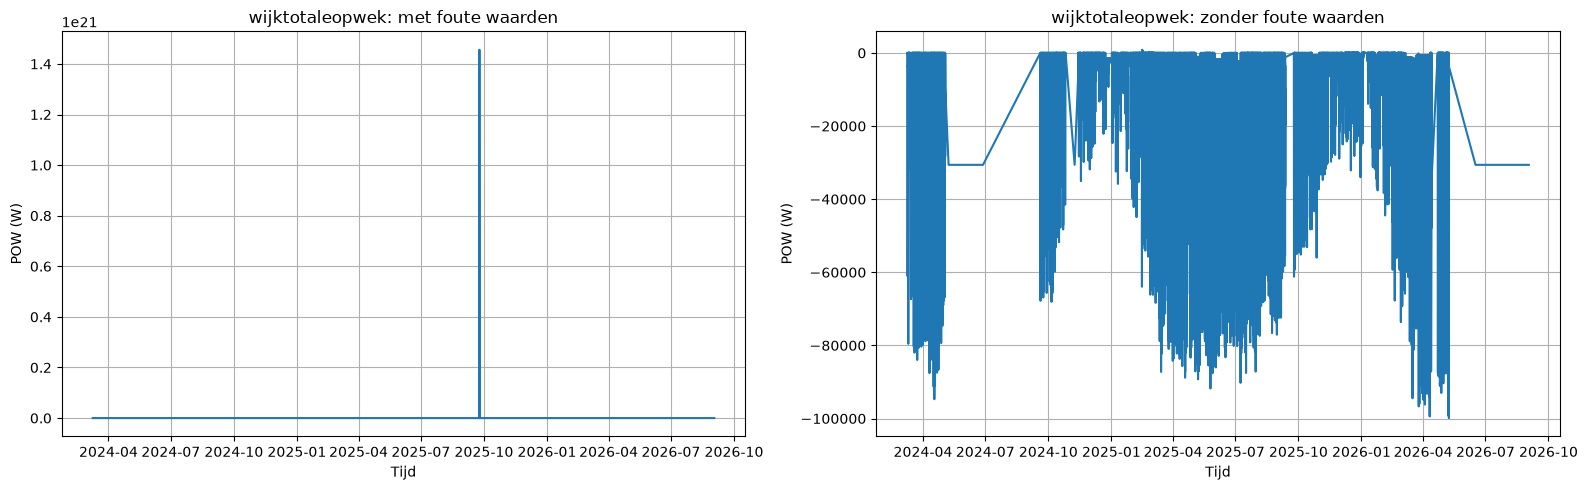

In [57]:
#Het apparaat met de meeste onmogelijke waarden
slechtste = onmogelijk_per_apparaat.index[0]
df_slechtste = df_carport[(df_carport["apparaat_kort"] == slechtste) & df_carport["POW"].notna()].sort_values("timestamp")
goed = df_slechtste["POW"].abs() <= MAX_VERMOGEN

fig, (ax_voor, ax_na) = plt.subplots(1, 2, figsize=(16, 5))

ax_voor.plot(df_slechtste["timestamp"], df_slechtste["POW"])
ax_voor.set_title(f"{slechtste}: met foute waarden")
ax_voor.set_xlabel("Tijd")
ax_voor.set_ylabel("POW (W)")
ax_voor.grid()

ax_na.plot(df_slechtste.loc[goed, "timestamp"], df_slechtste.loc[goed, "POW"])
ax_na.set_title(f"{slechtste}: zonder foute waarden")
ax_na.set_xlabel("Tijd")
ax_na.set_ylabel("POW (W)")
ax_na.grid()

plt.tight_layout()
plt.show()

6. De wijk-meters verwijderen

> Alle waarden boven de grens komen van de drie wijk meters: wijktotaalverbruik, wijktotaleopwek en wijkvirtuelehoofdmeter
>
> Deze meters tellen het verbruik en de opwek van alle huizen in de wijk bij elkaar op. Daardoor liggen hun waarden hoger dan bij de carport
>
> Op 24-09-2025 om 09:50 staat bij twee wijk meters tegelijk een waarde van 1,4·10²¹ W. Dat is wel echt een fout in de data
>
> We gebruiken de wijk meters niet. In dit project bestaat "de wijk" uit de drie locaties waarvan we data hebben (huis, middenhuis en carport). Het verbruik en de opwek daarvan kunnen we zelf berekenen door deze drie op te tellen
>
> Let op: de wijk meters meten de hele wijk, dus onze optelling van drie locaties is kleiner dan wat de wijk meters lieten zien
>
> Daarom worden de wijk meters hier in zijn geheel verwijderd

In [58]:
WIJK_METERS = ["wijktotaalverbruik-e4393cd3dfdb", "wijktotaleopwek-e4393cd3dfdb", "wijkvirtuelehoofdmeter-e4393cd3dfdb"]

df_carport = df_carport[~df_carport["ENAME"].isin(WIJK_METERS)]

#Controle: zijn er nog waarden boven de grens?
print("Waarden boven de grens over:", (df_carport["POW"].abs() > MAX_VERMOGEN).sum())

#Overgebleven apparaten met hun laagste en hoogste POW
df_carport.groupby("apparaat_kort")["POW"].agg(["min", "max"])

Waarden boven de grens over: 0


,min,max
apparaat_kort,,
hoofdaansluiting,-62131.763889,29689.216867
laadpaal1,0.000000,11079.548387
laadpaal2,0.000000,10943.078125
laadpaal3,0.000000,10859.528000
laadpaal4,0.000000,11119.310881
laadpaal5,0.000000,8010.236264
laadpaalbus,-1.000000,11216.414286
laadpaaltesla,-2.000000,11461.826087
overigverbruik,-32083.457447,35383.745856


7. Conclusie

> Na het verwijderen van de wijk-meters zitten er geen onmogelijke POW waarden meer in de data
>
> Alle overgebleven apparaten blijven binnen de 100 kW die de aansluiting van de carport kan leveren

### Missende waarden
___
Na het samenvoegen heeft elk apparaat één rij per timestamp. Toch ontbreken er waarden. Er zijn twee soorten:

> **Lege kolommen**: kolommen die nooit gevuld worden, omdat ze bij de apparaten hoorden die we al verwijderd hebben (zoals PRICE en forecast). Dit zijn geen echte missende waarden, deze kolommen kunnen weg
>
> **Gaten in de tijd**: een apparaat meet normaal elke 5 minuten, maar op sommige momenten is er geen POW waarde. Dit zijn de echte missende waarden

1. Overzicht van lege waarden per kolom (zelfde opbouw als notebook 02 Huis)

In [59]:
missing_overzicht = pd.DataFrame({
    "aantal_leeg": df_carport.isna().sum(),
    "percentage_leeg": (df_carport.isna().mean() * 100).round(2)
})

missing_overzicht.sort_values("percentage_leeg", ascending=False)

,aantal_leeg,percentage_leeg
CO2EQ,2060459,100.00
ESTYPE,2060459,100.00
forecast.ENE,2060459,100.00
PRICE,2060459,100.00
forecast.POW,2060459,100.00
CO2_EXP,1561026,75.76
CO2_IMP,1330693,64.58
ENE_CNT_EXP,1102573,53.51
ENE_EXP,1097293,53.25
CO2,880593,42.74


2. Kolommen die helemaal leeg zijn verwijderen

In [60]:
helemaal_leeg = missing_overzicht[missing_overzicht["percentage_leeg"] == 100].index.tolist()
print("Helemaal lege kolommen:", helemaal_leeg)

df_carport = df_carport.drop(columns=helemaal_leeg)

Helemaal lege kolommen: ['CO2EQ', 'ESTYPE', 'forecast.ENE', 'forecast.POW', 'PRICE']


3. POW op een vast raster van 5 minuten zetten

> Elk apparaat hoort elke 5 minuten een meting te hebben. Door alle momenten van 5 minuten onder elkaar te zetten, worden ontbrekende momenten zichtbaar als lege plek
>
> Een apparaat telt alleen mee van zijn eerste tot zijn laatste meting. Laadpaal 4 en 5 en de batterij zijn later begonnen, de tijd daarvoor is geen gat

In [61]:
import numpy as np

#Eén kolom per apparaat, één rij per timestamp (kan zonder gemiddelde, want er zijn geen dubbele meer)
pow_breed = df_carport.pivot(index="timestamp", columns="apparaat_kort", values="POW")

#Volledig raster van 5 minuten van de eerste tot de laatste timestamp
raster = pd.date_range(pow_breed.index.min(), pow_breed.index.max(), freq="5min")
pow_breed = pow_breed.reindex(raster)
pow_breed.index.name = "timestamp"

In [62]:
#Per apparaat: hoeveel metingen verwacht, hoeveel ontbreken er
def ontbrekend_overzicht(reeks):
    reeks = reeks.loc[reeks.first_valid_index():reeks.last_valid_index()]
    return pd.Series({
        "verwachte_metingen": len(reeks),
        "ontbrekend": reeks.isna().sum(),
        "percentage_ontbrekend": round(reeks.isna().mean() * 100, 2)
    })

ontbrekend_per_apparaat = pow_breed.apply(ontbrekend_overzicht).T.sort_values("percentage_ontbrekend", ascending=False)

ontbrekend_per_apparaat

,verwachte_metingen,ontbrekend,percentage_ontbrekend
apparaat_kort,,,
laadpaalbus,261576.0,201507.0,77.04
laadpaaltesla,261572.0,198909.0,76.04
laadpaal4,77079.0,36370.0,47.19
laadpaal5,77079.0,36370.0,47.19
zonnepanelen,261578.0,81357.0,31.10
victronaccu,159511.0,41842.0,26.23
hoofdaansluiting,261579.0,57871.0,22.12
laadpaal3,261579.0,57112.0,21.83
overigverbruik,261579.0,56504.0,21.60


4. Gaten indelen op lengte (zelfde categorieën als notebook 02 Huis)

> Een gat is een aantal lege plekken achter elkaar. Hoe langer het gat, hoe moeilijker het is om goed in te vullen

In [63]:
#Indeling op aantal ontbrekende metingen van 5 minuten
def categorie_gat(punten):
    if punten <= 2:
        return "5-10 min"
    if punten <= 11:
        return "15-55 min"
    if punten <= 71:
        return "1-6 uur"
    if punten <= 287:
        return "6-24 uur"
    return "meer dan 1 dag"

VOLGORDE = ["5-10 min", "15-55 min", "1-6 uur", "6-24 uur", "meer dan 1 dag"]

#Alle gaten van één apparaat met hun begin en lengte
def vind_gaten(reeks):
    reeks = reeks.loc[reeks.first_valid_index():reeks.last_valid_index()]
    leeg = reeks.isna()

    #Elk nieuw stuk van leeg of gevuld krijgt een eigen nummer
    blok = (leeg != leeg.shift()).cumsum()

    gaten = (pd.DataFrame({"start": reeks.index[leeg], "blok": blok[leeg].to_numpy()})
             .groupby("blok").agg(start=("start", "min"), punten=("start", "size")))
    return gaten.reset_index(drop=True)

alle_gaten = pd.concat({apparaat: vind_gaten(pow_breed[apparaat]) for apparaat in pow_breed.columns}, names=["apparaat", None])
alle_gaten = alle_gaten.reset_index(level=0).reset_index(drop=True)
alle_gaten["categorie"] = alle_gaten["punten"].apply(categorie_gat)

#Samenvatting zoals in notebook 02
alle_gaten.groupby("categorie").agg(aantal_gaten=("punten", "size"), ontbrekende_punten=("punten", "sum")).reindex(VOLGORDE)

,aantal_gaten,ontbrekende_punten
categorie,,
5-10 min,97861,101441
15-55 min,10691,63786
1-6 uur,4978,131236
6-24 uur,677,80909
meer dan 1 dag,160,548678


5. Per apparaat: welk deel van de tijd ontbreekt, en in hoe lange gaten

> Lichte kleur = korte gaten (makkelijk in te vullen), donkere kleur = lange gaten (moeilijk of niet in te vullen)

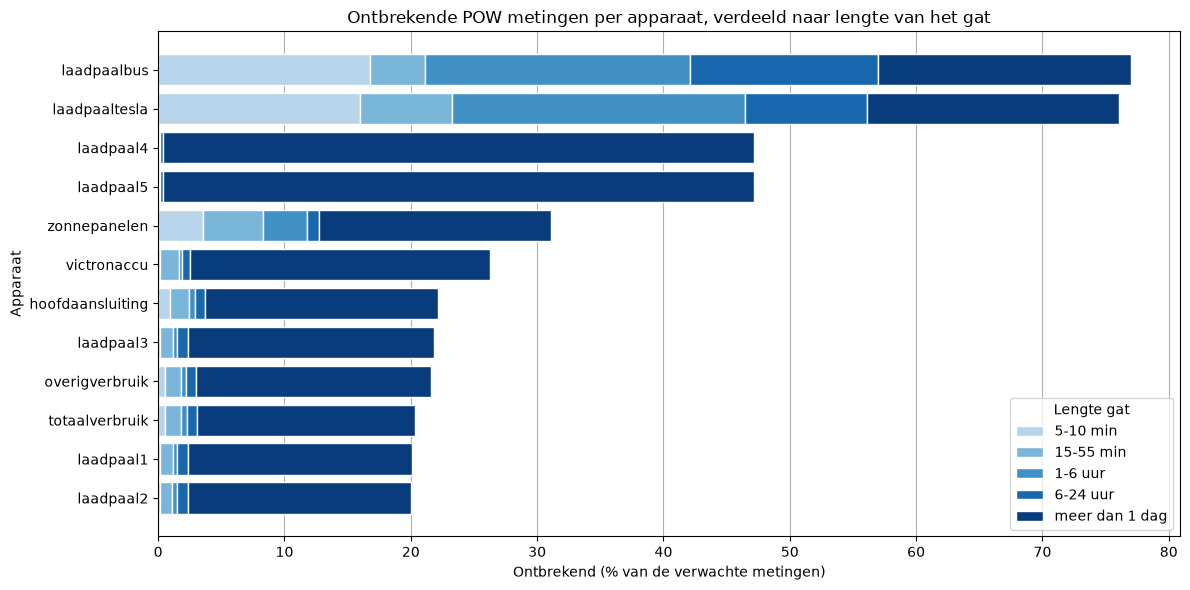

In [64]:
#Ontbrekende metingen per apparaat per categorie, als percentage van de verwachte metingen
gaten_per_apparaat = (alle_gaten.pivot_table(index="apparaat", columns="categorie", values="punten", aggfunc="sum", fill_value=0)
                      .reindex(columns=VOLGORDE, fill_value=0))
gaten_procent = gaten_per_apparaat.div(ontbrekend_per_apparaat["verwachte_metingen"], axis=0) * 100
gaten_procent = gaten_procent.loc[gaten_procent.sum(axis=1).sort_values().index]

#Eén kleur, van licht (kort gat) naar donker (lang gat)
kleuren = plt.cm.Blues(np.linspace(0.3, 0.95, len(VOLGORDE)))

plt.figure(figsize=(12, 6))
links = np.zeros(len(gaten_procent))
for categorie, kleur in zip(VOLGORDE, kleuren):
    plt.barh(gaten_procent.index, gaten_procent[categorie], left=links, color=kleur, edgecolor="white", linewidth=1, label=categorie)
    links += gaten_procent[categorie].to_numpy()

plt.xlabel("Ontbrekend (% van de verwachte metingen)")
plt.ylabel("Apparaat")
plt.title("Ontbrekende POW metingen per apparaat, verdeeld naar lengte van het gat")
plt.legend(title="Lengte gat")
plt.grid(axis="x")
plt.gca().set_axisbelow(True)
plt.tight_layout()
plt.show()

### Interpolatie: welke methode om gaten in te vullen
___
Er zijn drie logische manieren om een gat in te vullen:

> **Vorige waarde**: de laatste bekende waarde wordt doorgetrokken tot het gat voorbij is
>
> **Lineair**: een rechte lijn van de waarde vóór het gat naar de waarde na het gat
>
> **Zelfde tijd gisteren**: de waarde van precies 24 uur eerder

Het gemiddelde van de hele reeks gebruiken we niet: dat geeft een vlakke lijn die het dagritme (zon overdag, verbruik 's avonds) negeert.

**Verwachting.** In notebook 02 (huis) is de lag-correlatie berekend: de POW lijkt sterk op die van 5 minuten eerder (0,87), al veel minder op die van 1 uur eerder (0,49) en bijna niet op die van 6 uur eerder (0,11). Met die van 24 uur eerder is de samenhang weer hoger (0,43). Bij korte gaten zijn de waarden rond het gat dus de beste schatting, bij lange gaten de dag ervoor.

**Test.** Om dat niet alleen te beweren maar ook te laten zien:

> We nemen stukken data die wél compleet zijn, halen er zelf een gat in, vullen het met elke methode en vergelijken met de echte waarden
>
> De fout is de MAE (gemiddelde absolute fout): hoeveel watt de ingevulde waarde gemiddeld naast de echte zit. Lager is beter
>
> Per categorie wordt een typische gatlengte getest: 10 minuten, 30 minuten, 3 uur en 12 uur, telkens 300 keer op een willekeurige plek
>
> Gaten van meer dan 1 dag worden niet getest, die gaan we niet invullen (zie de keuze hieronder)

1. Testfunctie

In [65]:
DAG = 288  #aantal metingen van 5 minuten in een dag

#Categorie met een typische gatlengte in aantal metingen
TEST_GATEN = {"5-10 min": 2, "15-55 min": 6, "1-6 uur": 36, "6-24 uur": 144}

def test_methoden(reeks, punten, aantal_testen=300):
    #Plekken waar een hele dag vooraf, het gat en de meting erna allemaal gemeten zijn
    venster = DAG + punten + 1
    compleet = reeks.notna().astype(int).rolling(venster).sum() == venster
    eindes = np.flatnonzero(compleet.to_numpy())
    if len(eindes) == 0:
        return None

    #Altijd dezelfde willekeurige plekken, zodat de uitkomst herhaalbaar is
    rng = np.random.default_rng(42)
    gekozen = rng.choice(eindes, size=min(aantal_testen, len(eindes)), replace=False)

    fouten = {"vorige waarde": [], "lineair": [], "zelfde tijd gisteren": []}
    for einde in gekozen:
        stuk = reeks.iloc[einde - venster + 1 : einde + 1].copy()
        echt = stuk.iloc[DAG : DAG + punten].copy()

        #Zelf een gat maken
        stuk.iloc[DAG : DAG + punten] = np.nan

        gevuld = {
            "vorige waarde": stuk.ffill(),
            "lineair": stuk.interpolate(method="linear"),
            "zelfde tijd gisteren": stuk.shift(DAG)
        }
        for methode, waarden in gevuld.items():
            fouten[methode].append((waarden.iloc[DAG : DAG + punten] - echt).abs().mean())

    return {methode: np.mean(fout) for methode, fout in fouten.items()}

2. De test uitvoeren op de belangrijkste apparaten

In [66]:
TEST_APPARATEN = ["totaalverbruik", "zonnepanelen", "hoofdaansluiting", "victronaccu", "laadpaal1"]

resultaten = []
for apparaat in TEST_APPARATEN:
    if apparaat not in pow_breed.columns:
        continue
    for categorie, punten in TEST_GATEN.items():
        fout = test_methoden(pow_breed[apparaat], punten)
        if fout is not None:
            resultaten.append({"apparaat": apparaat, "categorie": categorie, **fout})

df_test = pd.DataFrame(resultaten).set_index(["apparaat", "categorie"]).round(1)

#Methode met de laagste fout per regel
df_test["beste_methode"] = df_test.idxmin(axis=1)

df_test

vorige waarde  lineair  zelfde tijd gisteren  \
apparaat         categorie                                                 
totaalverbruik   5-10 min           233.1    201.1                2351.2   
                 15-55 min          517.8    324.3                2449.5   
                 1-6 uur           1591.0   1066.9                2555.8   
                 6-24 uur          2178.6   2001.5                2429.7   
zonnepanelen     5-10 min          1652.8   1057.0                3807.1   
                 15-55 min         2306.1   1468.2                3821.0   
                 1-6 uur           6168.8   3169.0                4649.5   
                 6-24 uur         15094.4   9561.6                4110.9   
hoofdaansluiting 5-10 min          1551.4   1144.3                4950.1   
                 15-55 min         1595.2   1299.4                4625.2   
                 1-6 uur           3561.9   2337.3                4438.8   
                 6-24 uur          6208.9   4411.8                4429.4   
victronaccu      5-10 min          1151.4    941.6                4082.5   
                 15-55 min         1398.5   1079.0                3552.6   
                 1-6 uur           2510.0   1604.2                3558.5   
                 6-24 uur          4797.7   3588.7                3559.7   
laadpaal1        5-10 min            24.3     23.7                 423.0   
                 15-55 min           69.5     53.1                 394.3   
                 1-6 uur            236.7    186.2                 460.7   
                 6-24 uur           435.3    380.7                 537.3   

                                   beste_methode  
apparaat         categorie                        
totaalverbruik   5-10 min                lineair  
                 15-55 min               lineair  
                 1-6 uur                 lineair  
                 6-24 uur                lineair  
zonnepanelen     5-10 min                lineair  
                 15-55 min               lineair  
                 1-6 uur                 lineair  
                 6-24 uur   zelfde tijd gisteren  
hoofdaansluiting 5-10 min                lineair  
                 15-55 min               lineair  
                 1-6 uur                 lineair  
                 6-24 uur                lineair  
victronaccu      5-10 min                lineair  
                 15-55 min               lineair  
                 1-6 uur                 lineair  
                 6-24 uur   zelfde tijd gisteren  
laadpaal1        5-10 min                lineair  
                 15-55 min               lineair  
                 1-6 uur                 lineair  
                 6-24 uur                lineair

In [67]:
#Hoe vaak elke methode de beste is, per categorie
pd.crosstab(df_test.index.get_level_values("categorie"), df_test["beste_methode"]).reindex(list(TEST_GATEN))

beste_methode,lineair,zelfde tijd gisteren
row_0,,
5-10 min,5,0
15-55 min,5,0
1-6 uur,5,0
6-24 uur,3,2


3. De fout per methode in een grafiek, per apparaat

> Elke grafiek heeft een eigen y-as, omdat de apparaten heel verschillende vermogens hebben

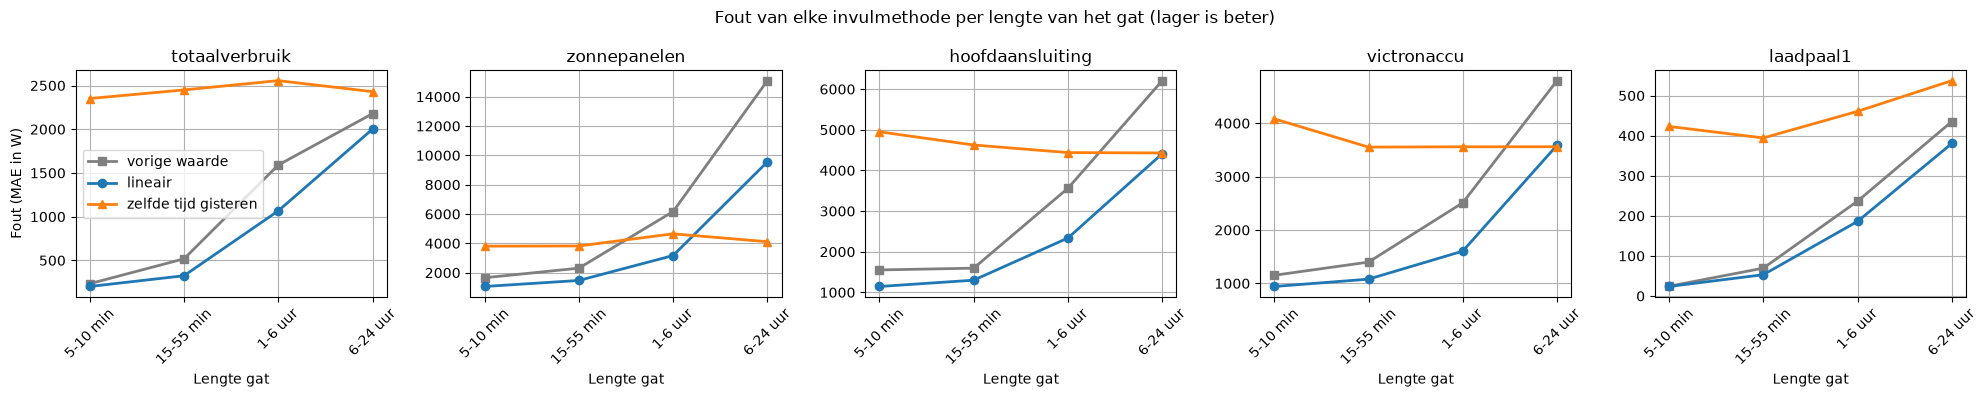

In [68]:
METHODEN = {"vorige waarde": ("tab:gray", "s"), "lineair": ("tab:blue", "o"), "zelfde tijd gisteren": ("tab:orange", "^")}
apparaten = df_test.index.get_level_values("apparaat").unique()

fig, assen = plt.subplots(1, len(apparaten), figsize=(4 * len(apparaten), 4), sharex=True)
for ax, apparaat in zip(np.atleast_1d(assen), apparaten):
    data = df_test.loc[apparaat].reindex(list(TEST_GATEN))
    for methode, (kleur, marker) in METHODEN.items():
        ax.plot(data.index, data[methode], color=kleur, marker=marker, linewidth=2, label=methode)
    ax.set_title(apparaat)
    ax.set_xlabel("Lengte gat")
    ax.tick_params(axis="x", rotation=45)
    ax.grid()

np.atleast_1d(assen)[0].set_ylabel("Fout (MAE in W)")
np.atleast_1d(assen)[0].legend()
plt.suptitle("Fout van elke invulmethode per lengte van het gat (lager is beter)")
plt.tight_layout()
plt.show()

4. Keuze en onderbouwing

> **Gaten tot 1 uur (5-10 min en 15-55 min): lineair.** In zo'n korte tijd verandert het vermogen weinig, dus een rechte lijn tussen de waarde voor en na het gat zit het dichtst bij de werkelijkheid
>
> **Gaten van 1 tot 24 uur (1-6 uur en 6-24 uur): zelfde tijd gisteren.** Over meerdere uren verandert het vermogen te veel voor een rechte lijn. Een lijn van 's ochtends naar 's middags mist bijvoorbeeld de hele zonpiek. De dag ervoor heeft wel hetzelfde dagritme
>
> **Gaten van meer dan 1 dag: niet invullen.** Dan zouden we hele dagen verzinnen. Deze periodes blijven leeg. SARIMAX kan zelf omgaan met lege waarden, of de periode wordt buiten de training gehouden
>
> Is de dag ervoor zelf ook leeg, dan blijft het gat leeg

5. De keuze toepassen

> Eerst worden de korte gaten lineair ingevuld, daarna de gaten tot 24 uur met de dag ervoor. Zo kan een kort gat van gisteren ook gebruikt worden voor een lang gat van vandaag

In [69]:
KORT = 11      #tot en met 55 minuten (11 ontbrekende metingen)
MIDDEL = 287   #tot en met 24 uur (287 ontbrekende metingen)

def vul_gaten(reeks):
    reeks = reeks.loc[reeks.first_valid_index():reeks.last_valid_index()]
    leeg = reeks.isna()

    #Lengte van het gat waar elke lege plek in valt
    blok = (leeg != leeg.shift()).cumsum()
    gat_lengte = leeg.groupby(blok).transform("sum")

    kort = leeg & (gat_lengte <= KORT)
    middel = leeg & (gat_lengte > KORT) & (gat_lengte <= MIDDEL)

    #Korte gaten: lineair
    gevuld = reeks.copy()
    gevuld[kort] = reeks.interpolate(method="linear")[kort]

    #Gaten tot 24 uur: zelfde tijd gisteren
    gevuld[middel] = gevuld.shift(DAG)[middel]
    return gevuld

pow_gevuld = pow_breed.apply(vul_gaten).reindex(pow_breed.index)

In [70]:
#Ontbrekende metingen voor en na het invullen
vergelijking = pd.DataFrame({
    "ontbrekend_voor": ontbrekend_per_apparaat["ontbrekend"],
    "ontbrekend_na": pow_gevuld.apply(ontbrekend_overzicht).T["ontbrekend"]
})
vergelijking["ingevuld"] = vergelijking["ontbrekend_voor"] - vergelijking["ontbrekend_na"]

vergelijking.sort_values("ontbrekend_na", ascending=False)

,ontbrekend_voor,ontbrekend_na,ingevuld
apparaat_kort,,,
laadpaalbus,201507.0,132118.0,69389.0
laadpaaltesla,198909.0,119115.0,79794.0
zonnepanelen,81357.0,51198.0,30159.0
laadpaal3,57112.0,51173.0,5939.0
overigverbruik,56504.0,48916.0,7588.0
hoofdaansluiting,57871.0,48318.0,9553.0
laadpaal1,52587.0,46607.0,5980.0
laadpaal2,52426.0,46453.0,5973.0
totaalverbruik,53195.0,45432.0,7763.0


6. Voorbeeld: een ingevuld gat bij totaalverbruik

> Blauw is gemeten, oranje is ingevuld

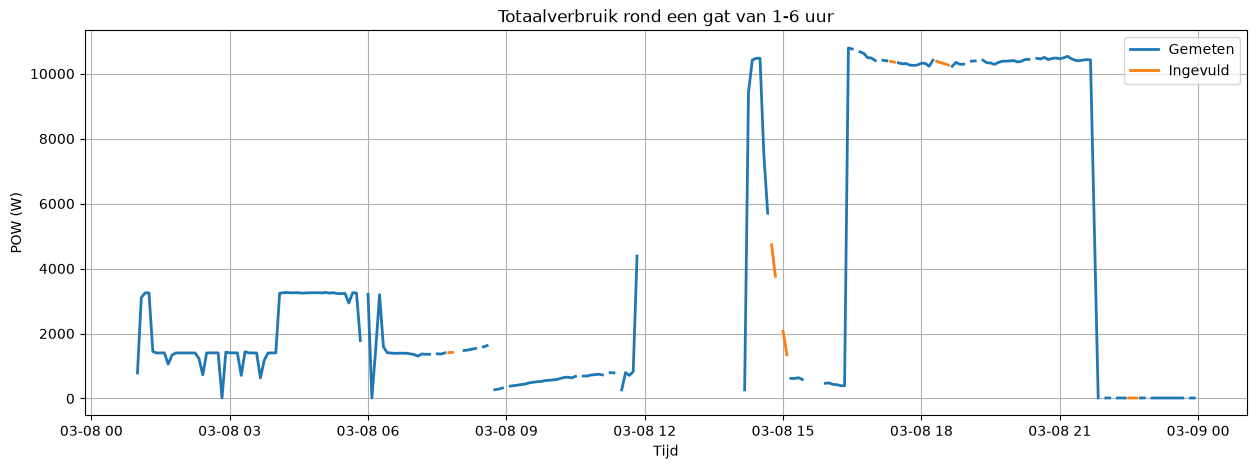

In [71]:
#Eerste gat van 1-6 uur bij totaalverbruik, anders het eerste gat van 15-55 min
gaten_totaal = alle_gaten[alle_gaten["apparaat"] == "totaalverbruik"]
for categorie in ["1-6 uur", "15-55 min"]:
    if (gaten_totaal["categorie"] == categorie).any():
        voorbeeld = gaten_totaal[gaten_totaal["categorie"] == categorie].iloc[0]
        break

van = voorbeeld["start"] - pd.Timedelta(hours=12)
tot = voorbeeld["start"] + pd.Timedelta(hours=12)
gemeten = pow_breed.loc[van:tot, "totaalverbruik"]
ingevuld = pow_gevuld.loc[van:tot, "totaalverbruik"]

plt.figure(figsize=(15, 5))
plt.plot(gemeten.index, gemeten, color="tab:blue", linewidth=2, label="Gemeten")
plt.plot(ingevuld.index, ingevuld.where(gemeten.isna()), color="tab:orange", linewidth=2, label="Ingevuld")

plt.xlabel("Tijd")
plt.ylabel("POW (W)")
plt.title(f"Totaalverbruik rond een gat van {voorbeeld['categorie']}")
plt.legend()
plt.grid()
plt.show()

7. Welke data gebruiken we waarvoor

> `pow_gevuld` (met ingevulde gaten) is bedoeld voor het voorspellingsmodel
>
> `pow_breed` (zonder ingevulde gaten) gebruiken we voor analyses zoals de correlaties hieronder, omdat ingevulde waarden geschat zijn en geen echte metingen

### Correlaties tussen de POW waarden
___
> Correlatie geeft aan hoe sterk twee apparaten samen omhoog en omlaag gaan: 1 = altijd samen omhoog, -1 = als de een omhoog gaat gaat de ander omlaag, 0 = geen verband
>
> **Pearson** kijkt of er een rechte-lijn verband is, **Spearman** alleen of ze in dezelfde richting bewegen. Zelfde aanpak als notebook 02 Huis
>
> Berekend op de gemeten waarden, zonder ingevulde gaten. Ingevulde waarden zijn geschat en zouden de correlatie sterker laten lijken dan hij is
>
> Een paar apparaten telt alleen mee als ze minimaal 1.000 keer tegelijk gemeten zijn
>
> Let op: zonnepanelen hebben een negatieve POW bij opwek. Een negatieve correlatie met zonnepanelen betekent dus: meer zon → meer van dit apparaat

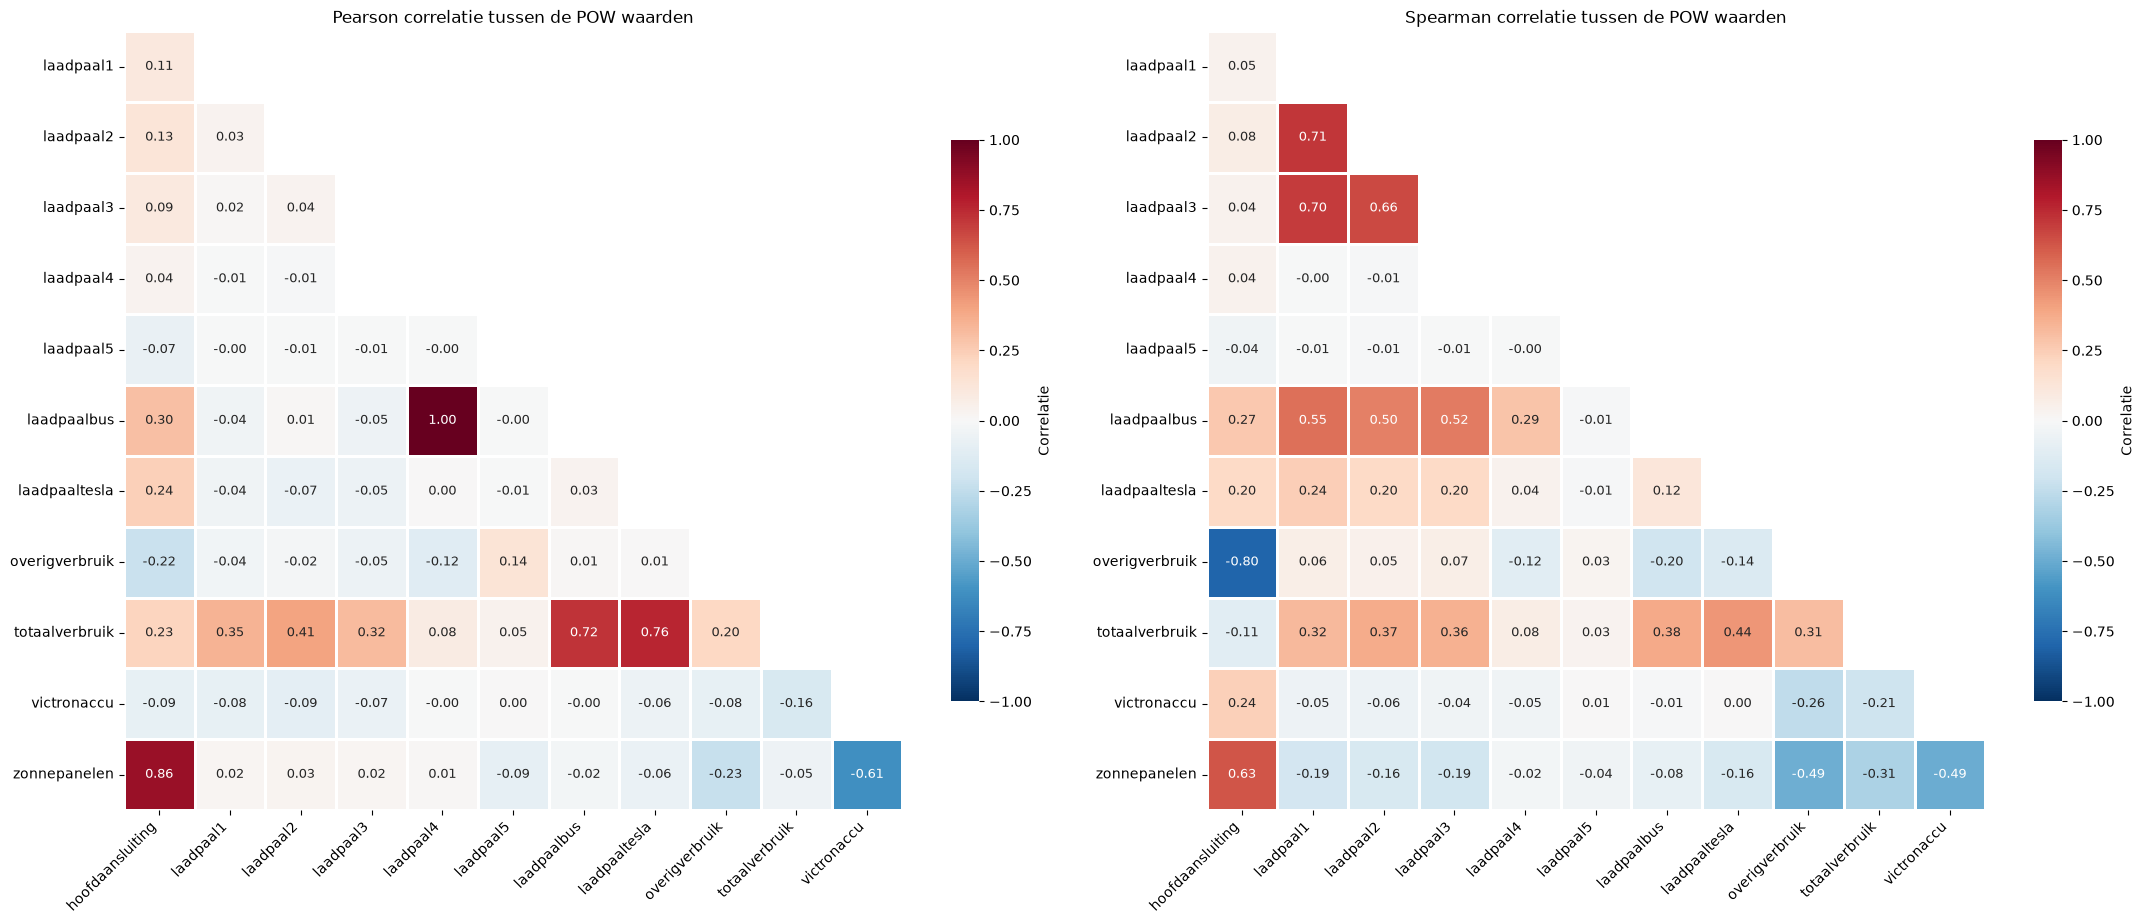

In [72]:
import seaborn as sns

pearson = pow_breed.corr(method="pearson", min_periods=1000)
spearman = pow_breed.corr(method="spearman", min_periods=1000)

#Alleen de onderste helft tonen: de bovenste helft is hetzelfde, gespiegeld
#De eerste rij en laatste kolom zouden dan leeg zijn, die worden weggelaten
def onderste_helft(matrix):
    matrix = matrix.iloc[1:, :-1]
    masker = np.triu(np.ones_like(matrix, dtype=bool), k=1)
    return matrix, masker

fig, assen = plt.subplots(1, 2, figsize=(22, 9))
for ax, matrix, naam in zip(assen, [pearson, spearman], ["Pearson", "Spearman"]):
    matrix, masker = onderste_helft(matrix)
    sns.heatmap(matrix, mask=masker, annot=True, fmt=".2f", annot_kws={"size": 9},
                cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True,
                linewidths=1, linecolor="white", cbar_kws={"shrink": 0.7, "label": "Correlatie"}, ax=ax)
    ax.set_title(f"{naam} correlatie tussen de POW waarden")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=45)
    plt.setp(ax.get_xticklabels(), ha="right")

plt.tight_layout()
plt.show()

1. Correlatie van elk apparaat met totaalverbruik, gesorteerd op sterkte (zelfde tabel als notebook 02 Huis)

In [73]:
#Aantal momenten waarop beide apparaten gemeten zijn
gemeten = pow_breed.notna().astype(int)
gezamenlijk = gemeten.T @ gemeten

corr_totaal = pd.DataFrame({
    "pearson": pearson["totaalverbruik"],
    "spearman": spearman["totaalverbruik"],
    "gezamenlijke_metingen": gezamenlijk["totaalverbruik"]
}).drop("totaalverbruik").round(2)

corr_totaal.loc[corr_totaal["pearson"].abs().sort_values(ascending=False).index]

,pearson,spearman,gezamenlijke_metingen
apparaat_kort,,,
laadpaaltesla,0.76,0.44,62560
laadpaalbus,0.72,0.38,59978
laadpaal2,0.41,0.37,207335
laadpaal1,0.35,0.32,207195
laadpaal3,0.32,0.36,202654
hoofdaansluiting,0.23,-0.11,203664
overigverbruik,0.20,0.31,204892
victronaccu,-0.16,-0.21,117661
laadpaal4,0.08,0.08,40646


2. Zo lees je de heatmap

> Donkerrood = sterk samen omhoog, donkerblauw = sterk tegengesteld, wit = geen verband
>
> Een groot verschil tussen Pearson en Spearman betekent dat het verband er wel is, maar niet als rechte lijn. Dat zie je vaak bij de laadpalen: die staan meestal op 0 en springen dan ineens naar enkele kW
>
> Een lege cel betekent dat de twee apparaten minder dan 1.000 keer tegelijk gemeten zijn

### Rekentest: is het laden gelijk aan het totaalverbruik?
___
Vraag: is het verbruik van alle laadpalen samen gelijk aan het totaalverbruik van de carport?

> Als dat zo is, meet totaalverbruik alleen de laadpalen
>
> Als totaalverbruik hoger is, zit er nog ander verbruik in. Daarom testen we ook: laadpalen + overigverbruik = totaalverbruik?
>
> We gebruiken de gemeten waarden (`pow_breed`), zonder ingevulde gaten, zodat we echte metingen met elkaar vergelijken

1. Alle laadpalen per timestamp bij elkaar optellen

> Vóór de eerste meting van een laadpaal bestond die laadpaal nog niet (zoals laadpaal 4 en 5), die telt daar mee als 0 W
>
> Na de laatste meting van de laadpalen is er geen data meer, die periode wordt niet meegenomen
>
> Een moment telt alleen mee als alle laadpalen die er op dat moment waren ook echt gemeten zijn

In [74]:
LAADPALEN = [kolom for kolom in pow_breed.columns if kolom.startswith("laadpaal")]

laadpalen = pow_breed[LAADPALEN].copy()
for laadpaal in LAADPALEN:
    #Voor de eerste meting bestond de laadpaal nog niet: 0 W
    laadpalen.loc[:laadpalen[laadpaal].first_valid_index(), laadpaal] = laadpalen[laadpaal].fillna(0)

#Alleen tot de laatste meting van de laadpalen
einde_laadpalen = min(pow_breed[laadpaal].last_valid_index() for laadpaal in LAADPALEN)
laadpalen = laadpalen.loc[:einde_laadpalen]

#Som van alle laadpalen, alleen als geen enkele laadpaal ontbreekt
balans = pd.DataFrame({
    "laadpalen": laadpalen.sum(axis=1, min_count=len(LAADPALEN)).where(laadpalen.notna().all(axis=1)),
    "overigverbruik": pow_breed.loc[:einde_laadpalen, "overigverbruik"],
    "totaalverbruik": pow_breed.loc[:einde_laadpalen, "totaalverbruik"]
}).dropna()

print("Aantal momenten om te vergelijken:", len(balans))
print("Periode:", balans.index.min(), "tot", balans.index.max())

Aantal momenten om te vergelijken: 26906
Periode: 2024-03-08 01:00:00+01:00 tot 2026-09-02 08:10:00+02:00


2. Twee rekentests uitvoeren

> **Test 1:** laadpalen = totaalverbruik
>
> **Test 2:** laadpalen + overigverbruik = totaalverbruik
>
> Per test kijken we naar het verschil met totaalverbruik. Hoe dichter bij 0 W, hoe beter de som klopt

In [75]:
balans["laadpalen_plus_overig"] = balans["laadpalen"] + balans["overigverbruik"]

#Verschil met het totaalverbruik per moment
verschil = pd.DataFrame({
    "test 1: laadpalen": balans["totaalverbruik"] - balans["laadpalen"],
    "test 2: laadpalen + overig": balans["totaalverbruik"] - balans["laadpalen_plus_overig"]
})

#Samenvatting per test
def samenvatting(verschil_reeks, som):
    return pd.Series({
        "correlatie met totaal": som.corr(balans["totaalverbruik"]),
        "gemiddeld verschil (W)": verschil_reeks.mean(),
        "mediaan verschil (W)": verschil_reeks.median(),
        "gemiddeld absoluut verschil (W)": verschil_reeks.abs().mean(),
        "% momenten binnen 100 W": (verschil_reeks.abs() <= 100).mean() * 100
    })

rekentest = pd.DataFrame({
    "test 1: laadpalen": samenvatting(verschil["test 1: laadpalen"], balans["laadpalen"]),
    "test 2: laadpalen + overig": samenvatting(verschil["test 2: laadpalen + overig"], balans["laadpalen_plus_overig"])
}).round(2)

rekentest

,test 1: laadpalen,test 2: laadpalen + overig
correlatie met totaal,0.99,1.00
gemiddeld verschil (W),82.27,-40.55
mediaan verschil (W),37.21,-0.01
gemiddeld absoluut verschil (W),209.97,44.27
% momenten binnen 100 W,49.51,95.45


3. Totaal over de hele periode in kWh

> Energie per meting (kWh) = POW (W) * 5/60 uur / 1000, net als bij het laden per week

In [76]:
kwh_totaal = (balans[["laadpalen", "overigverbruik", "laadpalen_plus_overig", "totaalverbruik"]] * (5 / 60) / 1000).sum().round()

print("Laadpalen samen (kWh):", kwh_totaal["laadpalen"])
print("Overigverbruik (kWh):", kwh_totaal["overigverbruik"])
print("Laadpalen + overig (kWh):", kwh_totaal["laadpalen_plus_overig"])
print("Totaalverbruik (kWh):", kwh_totaal["totaalverbruik"])
print(f"Aandeel laadpalen in totaalverbruik: {kwh_totaal['laadpalen'] / kwh_totaal['totaalverbruik'] * 100:.1f}%")

Laadpalen samen (kWh): 4483.0
Overigverbruik (kWh): 275.0
Laadpalen + overig (kWh): 4759.0
Totaalverbruik (kWh): 4668.0
Aandeel laadpalen in totaalverbruik: 96.0%


4. Visuele controle

> Bovenaan: elke stip is één moment. Ligt de stip op de stippellijn, dan is de som precies gelijk aan het totaalverbruik
>
> Daaronder: twee dagen naast elkaar, zodat je ziet waar de lijnen afwijken

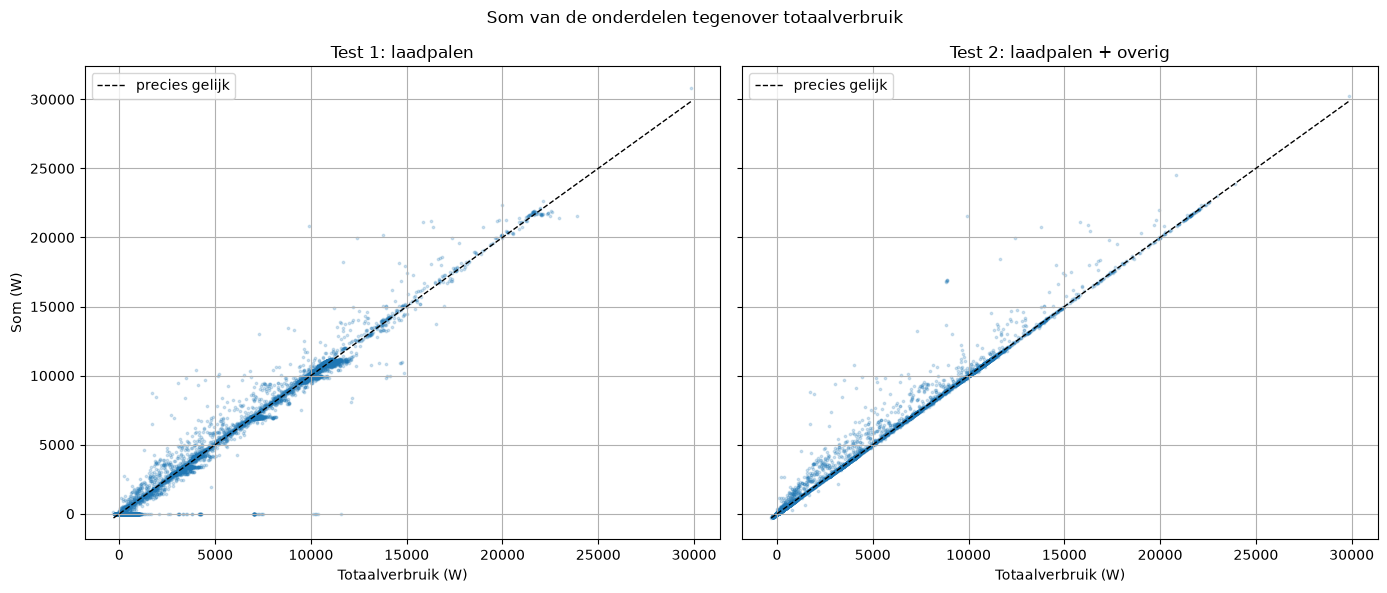

In [77]:
#Willekeurige steekproef, anders zijn het te veel stippen
steekproef = balans.sample(min(20_000, len(balans)), random_state=42)
grens = [steekproef["totaalverbruik"].min(), steekproef["totaalverbruik"].max()]

fig, (ax_test1, ax_test2) = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
for ax, kolom, titel in [(ax_test1, "laadpalen", "Test 1: laadpalen"),
                         (ax_test2, "laadpalen_plus_overig", "Test 2: laadpalen + overig")]:
    ax.scatter(steekproef["totaalverbruik"], steekproef[kolom], s=3, alpha=0.2, color="tab:blue")
    ax.plot(grens, grens, color="black", linestyle="--", linewidth=1, label="precies gelijk")
    ax.set_title(titel)
    ax.set_xlabel("Totaalverbruik (W)")
    ax.legend()
    ax.grid()
ax_test1.set_ylabel("Som (W)")

plt.suptitle("Som van de onderdelen tegenover totaalverbruik")
plt.tight_layout()
plt.show()

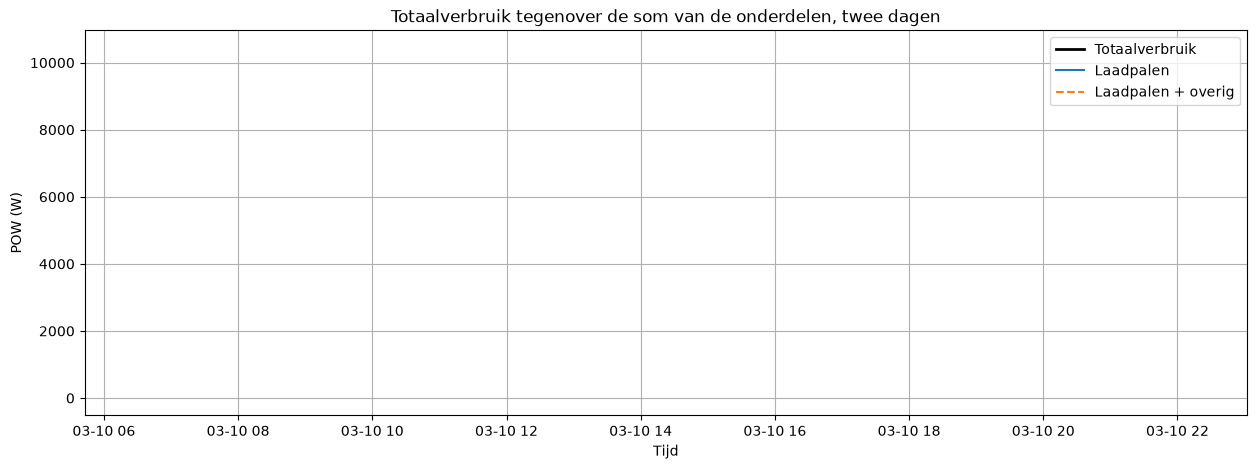

In [78]:
#Twee volledige dagen uit de vergelijking, asfreq zorgt dat de lijn bij een gat onderbroken wordt
week_start = balans.index.min().normalize() + pd.Timedelta(days=1)
week = balans.loc[week_start : week_start + pd.Timedelta(days=2)].asfreq("5min")

plt.figure(figsize=(15, 5))
plt.plot(week.index, week["totaalverbruik"], color="black", linewidth=2, label="Totaalverbruik")
plt.plot(week.index, week["laadpalen"], color="tab:blue", label="Laadpalen")
plt.plot(week.index, week["laadpalen_plus_overig"], color="tab:orange", linestyle="--", label="Laadpalen + overig")

plt.xlabel("Tijd")
plt.ylabel("POW (W)")
plt.title("Totaalverbruik tegenover de som van de onderdelen, twee dagen")
plt.legend()
plt.grid()
plt.show()

5. Zo lees je de uitkomst

> **Test 1 klopt** (verschil rond 0 W): totaalverbruik is alleen het laden van de auto's
>
> **Test 1 te laag, test 2 klopt**: totaalverbruik = laadpalen + overig verbruik (zoals verlichting en apparatuur). Overigverbruik is dan waarschijnlijk berekend als totaal min laadpalen
>
> **Beide tests kloppen niet**: er zit nog een onderdeel in het totaal dat niet apart gemeten wordt, of een van de meters meet anders (bv. andersom aangesloten). Dit is dan een vraag voor Pieter
>
> Een klein verschil (enkele tientallen watts) is normaal: de meters meten niet op exact hetzelfde moment en hebben elk een kleine meetfout